# Outlier Detection, Outlier Handling & Missing Value Analysis

## Objectives of this Notebook

1. Detect unusual observations using the methods covered in the lecture notes: **Boxplot/IQR, Histogram, Scatter Plot and Z-score**.
2. Compare IQR and Z-score results for the selected numerical variables.
3. Study the effect of outlier handling using Winsorization and IQR-based removal.
4. Analyze missing values in the processed datasets.
5. Investigate whether review-comment availability is associated with customer ratings and delivery lateness.
6. Conduct a masking experiment by hiding 15% of known product measurements and comparing Mean, Median, kNN and Multiple Imputation (MICE) using MAE and RMSE; Mode imputation is demonstrated for categorical data.


In [1]:
import warnings
import os
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)


# 1.Load processed datasets

In [2]:
# Locate the processed-data folder.
# This supports both the original project structure and opening the notebook
# from the same folder that contains PROCESSED_DATA.
if os.path.isdir("PROCESSED_DATA"):
    data_dir = "PROCESSED_DATA"
elif os.path.isdir("../PROCESSED_DATA"):
    data_dir = "../PROCESSED_DATA"
else:
    raise FileNotFoundError(
        "PROCESSED_DATA folder was not found. Place this notebook in the project "
        "folder or in the folder containing PROCESSED_DATA."
    )

master_orders = pd.read_csv(os.path.join(data_dir, "master_orders.csv"))
master_sellers = pd.read_csv(os.path.join(data_dir, "master_sellers.csv"))
cleaned_products = pd.read_csv(os.path.join(data_dir, "cleaned_products.csv"))
cleaned_items = pd.read_csv(os.path.join(data_dir, "cleaned_items.csv"))
cleaned_reviews = pd.read_csv(os.path.join(data_dir, "cleaned_reviews.csv"))

datasets = {
    "master_orders": master_orders,
    "master_sellers": master_sellers,
    "cleaned_products": cleaned_products,
    "cleaned_items": cleaned_items,
    "cleaned_reviews": cleaned_reviews
}

for name, data in datasets.items():
    print(f"{name} shape: {data.shape}")

master_orders shape: (99441, 59)
master_sellers shape: (3095, 25)
cleaned_products shape: (32951, 11)
cleaned_items shape: (112650, 10)
cleaned_reviews shape: (98673, 7)


### 1.1 Initial Dataset Inspection

The initial inspection checks the available columns, data types and missing values. This helps confirm that the processed files have the expected structure before applying statistical methods.

In [3]:
for name, data in datasets.items():
    print("\n" + "=" * 65)
    print(name.upper())
    print("=" * 65)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("Total missing values:", data.isnull().sum().sum())


MASTER_ORDERS
Shape: (99441, 59)
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'item_count', 'distinct_products', 'distinct_sellers', 'primary_seller_id', 'primary_product_id', 'primary_category', 'total_price', 'total_freight', 'total_weight_g', 'total_volume_cm3', 'shipping_limit_date', 'order_total_value', 'freight_ratio', 'payment_total', 'max_installments', 'payment_methods_count', 'primary_payment_type', 'review_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'has_comment', 'seller_zip_code_prefix', 'seller_city', 'seller_state', 'cust_lat', 'cust_lng', 'seller_lat', 'seller_lng', 'approval_hours', 'seller_handling_days', 'carrier_transit_days', 'total_delivery_days', 'estimated_delivery_days', 'da

## 2. Outlier Detection

### Purpose

An outlier is an observation that differs considerably from the majority of the data. In the DELTA project, unusual values may represent genuine high-value orders, unusually heavy products, long delivery times, or data-quality problems.

Outliers should not be removed automatically. They must first be detected and investigated because genuine extreme deliveries and high-value transactions may contain important business information.

The following methods:

1. **Boxplot / IQR:** Uses quartiles and the 1.5 × IQR fences to identify potential outliers.
2. **Histogram:** Shows the distribution and helps identify isolated bars separated from the main body of observations.
3. **Scatter Plot:** Helps identify unusual combinations of two variables.
4. **Z-score:** Measures how many standard deviations an observation lies from the mean. The lecture uses an absolute Z-score threshold of 3, assuming approximately bell-shaped data.

### 2.1 Selection of Numerical Variables

Outlier detection is performed on relevant numerical variables from the order, item and product datasets. Only columns that exist in the corresponding processed dataset are selected.

In [4]:
# Relevant order-level variables
order_outlier_candidates = [
    "total_price", "total_freight", "total_weight_g",
    "total_volume_cm3", "approval_hours",
    "seller_handling_days", "carrier_transit_days",
    "total_delivery_days", "days_late", "distance_km"
]

# Relevant item-level variables
item_outlier_candidates = [
    "price", "freight_value", "product_weight_g",
    "product_volume_cm3"
]

# Relevant product-level variables
product_outlier_candidates = [
    "product_name_length", "product_description_length",
    "product_photos_qty", "product_weight_g",
    "product_length_cm", "product_height_cm",
    "product_width_cm", "product_volume_cm3"
]

def available_numeric_data(data, candidates):
    selected = [c for c in candidates if c in data.columns]
    result = data[selected].apply(pd.to_numeric, errors="coerce")
    return result, selected

orders_numeric, order_columns = available_numeric_data(
    master_orders, order_outlier_candidates
)
items_numeric, item_columns = available_numeric_data(
    cleaned_items, item_outlier_candidates
)
products_numeric, product_columns = available_numeric_data(
    cleaned_products, product_outlier_candidates
)

outlier_datasets = {
    "Orders": orders_numeric,
    "Items": items_numeric,
    "Products": products_numeric
}

print("Order variables:", order_columns)
print("Item variables:", item_columns)
print("Product variables:", product_columns)

Order variables: ['total_price', 'total_freight', 'total_weight_g', 'total_volume_cm3', 'approval_hours', 'seller_handling_days', 'carrier_transit_days', 'total_delivery_days', 'days_late', 'distance_km']
Item variables: ['price', 'freight_value', 'product_weight_g', 'product_volume_cm3']
Product variables: ['product_name_length', 'product_description_length', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_volume_cm3']


### 2.2 Visual Identification of Outliers Using Boxplots

Boxplots provide a visual indication of extreme observations. Points beyond the whiskers are potential outliers according to the boxplot rule; they are not automatically errors.

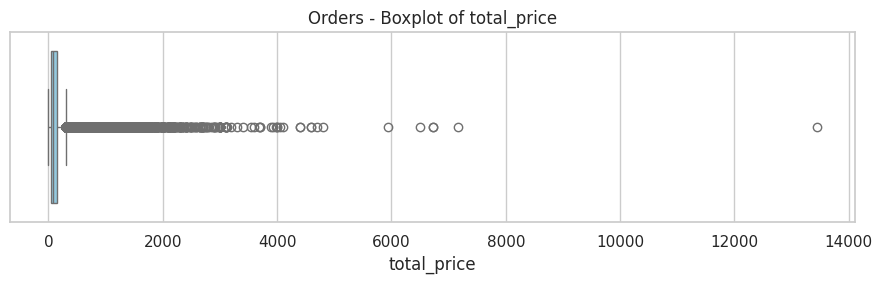

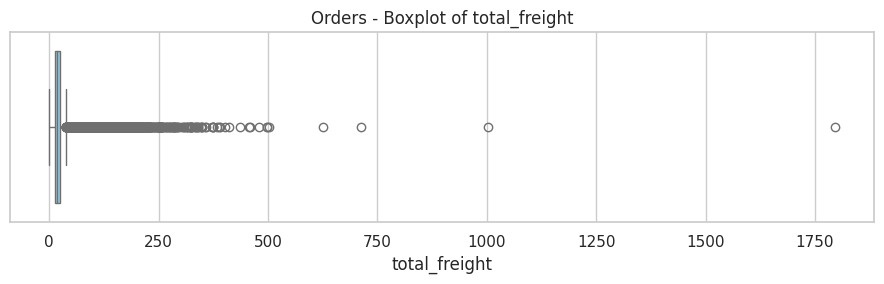

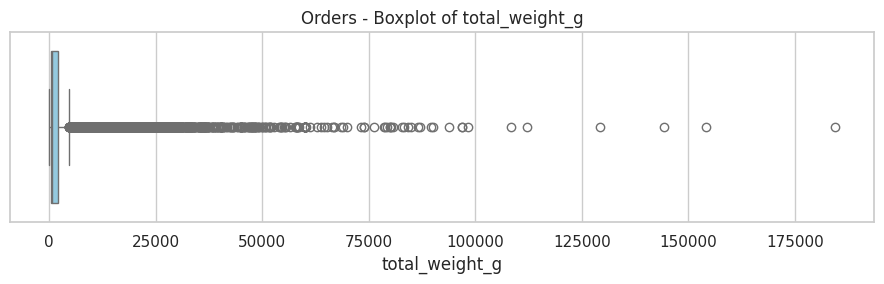

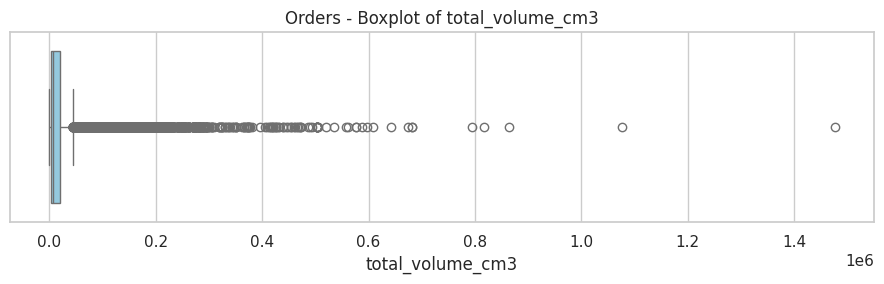

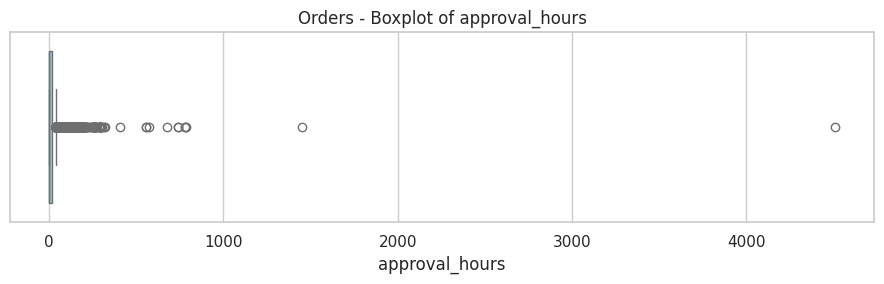

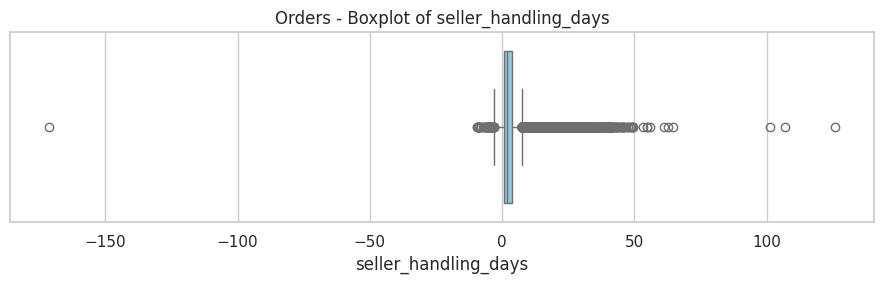

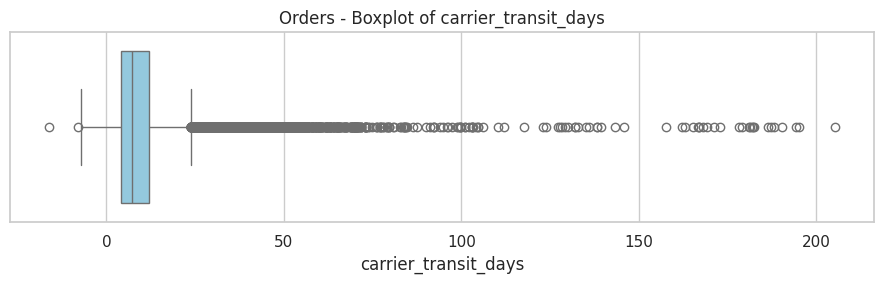

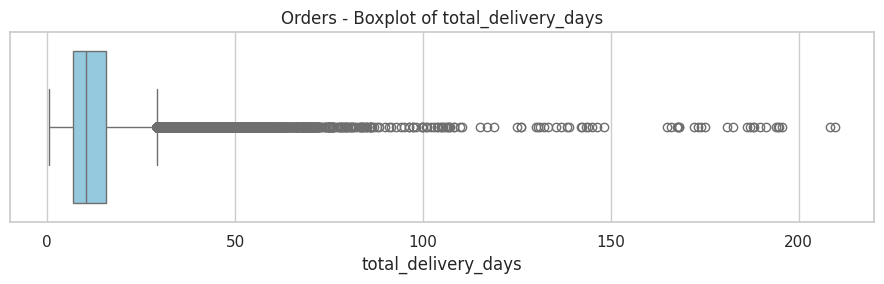

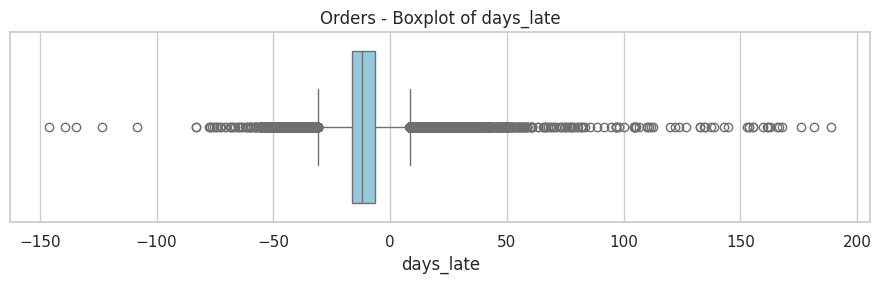

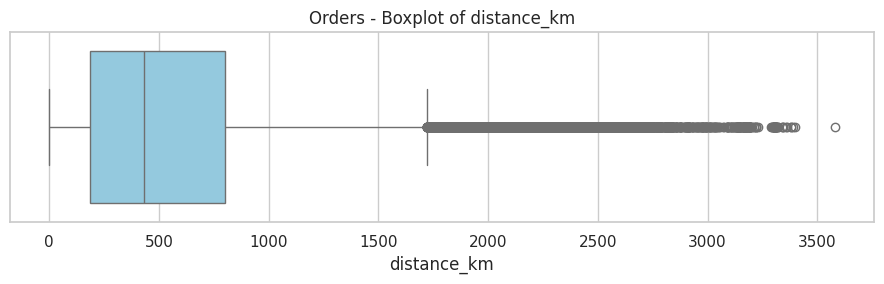

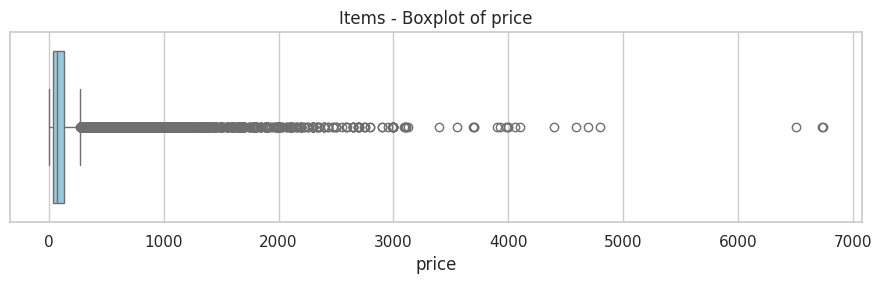

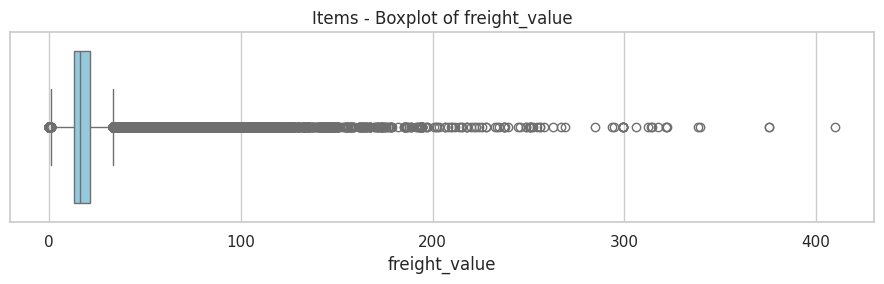

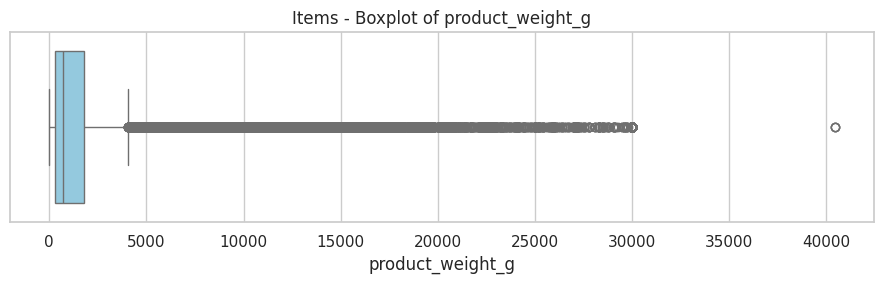

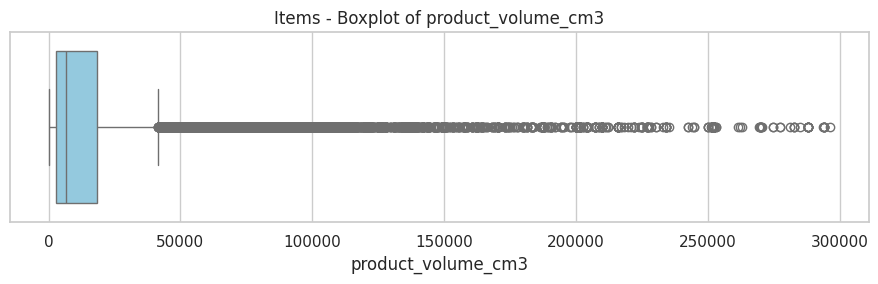

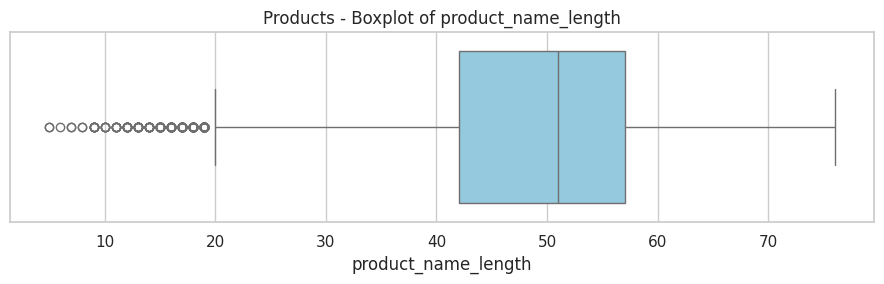

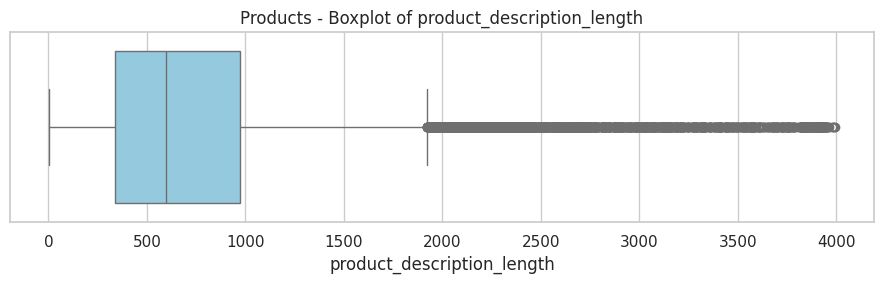

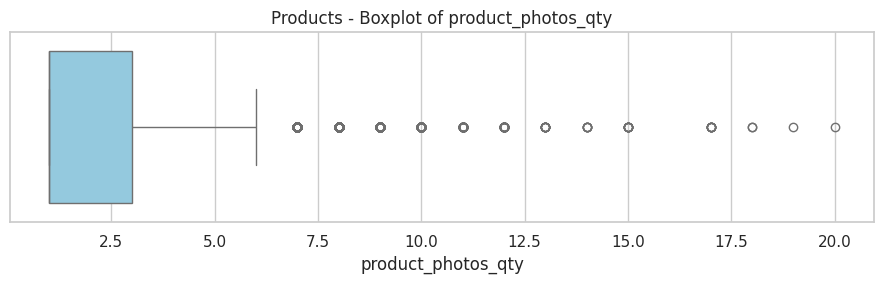

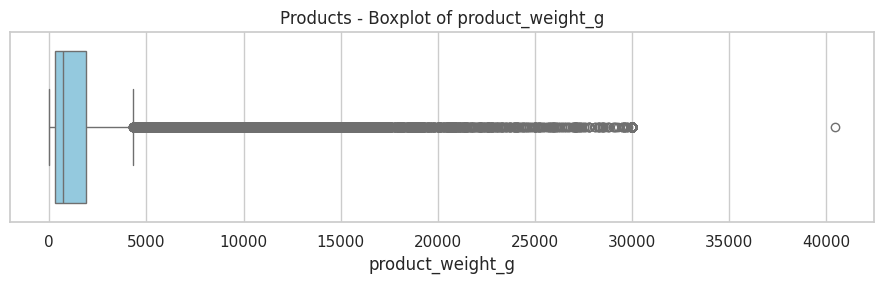

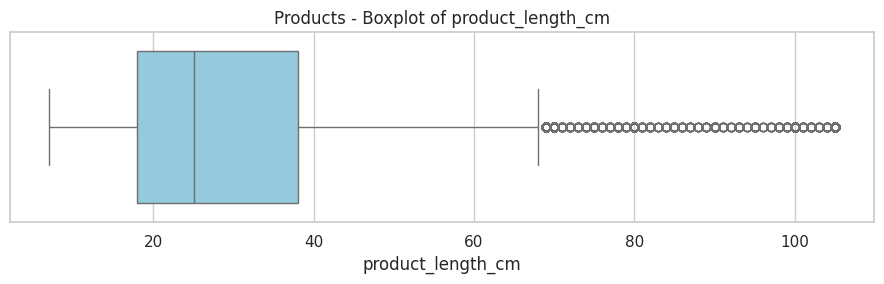

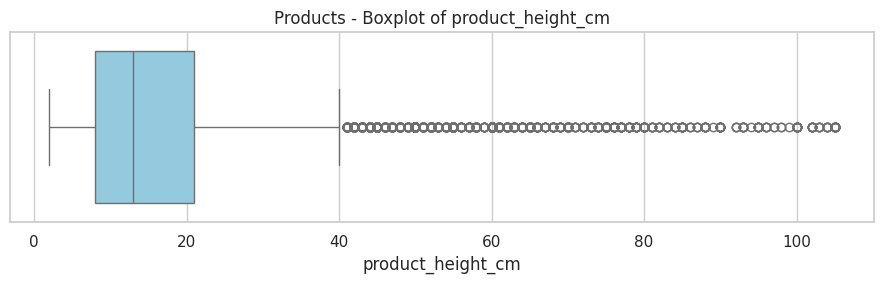

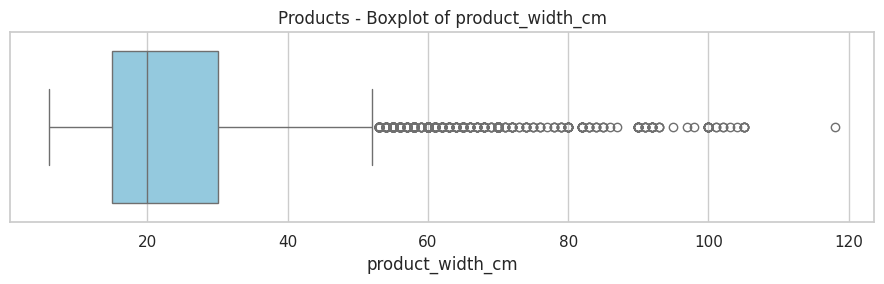

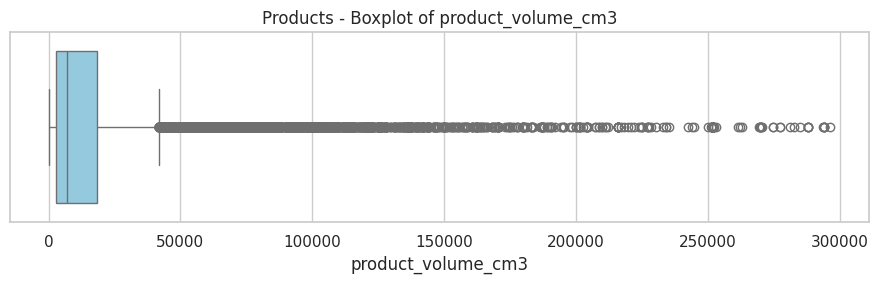

In [5]:
for dataset_name, data in outlier_datasets.items():
    for column in data.columns:
        plt.figure(figsize=(9, 3))
        sns.boxplot(x=data[column], color="skyblue")
        plt.title(f"{dataset_name} - Boxplot of {column}")
        plt.xlabel(column)
        plt.tight_layout()
        plt.show()

### 2.3 IQR Method

The Interquartile Range is calculated as:

\[
IQR = Q_3 - Q_1
\]

The lower and upper fences are:

\[
Lower = Q_1 - 1.5(IQR)
\]

\[
Upper = Q_3 + 1.5(IQR)
\]

Values below the lower fence or above the upper fence are flagged as potential outliers.

In [6]:
iqr_flags = {}

for dataset_name, data in outlier_datasets.items():
    flags = pd.DataFrame(index=data.index)

    for column in data.columns:
        values = data[column].dropna()
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr_value = q3 - q1

        lower_bound = q1 - 1.5 * iqr_value
        upper_bound = q3 + 1.5 * iqr_value

        flags[column] = (
            (data[column] < lower_bound) |
            (data[column] > upper_bound)
        ).fillna(False)

    iqr_flags[dataset_name] = flags

    print("\n", dataset_name, "- IQR Outlier Counts")
    display(flags.sum().to_frame("Outlier Count"))


 Orders - IQR Outlier Counts


,Outlier Count
total_price,7913
total_freight,9941
total_weight_g,13804
total_volume_cm3,9164
approval_hours,9141
seller_handling_days,5660
carrier_transit_days,5071
total_delivery_days,4899
days_late,4875
distance_km,7622



 Items - IQR Outlier Counts


,Outlier Count
price,8427
freight_value,12134
product_weight_g,15807
product_volume_cm3,10004



 Products - IQR Outlier Counts


,Outlier Count
product_name_length,290
product_description_length,2078
product_photos_qty,849
product_weight_g,4551
product_length_cm,1380
product_height_cm,1892
product_width_cm,912
product_volume_cm3,3262


### 2.4 Z-score Method

The Z-score measures the distance of an observation from the mean in standard deviation units:

\[
Z = \frac{x - \mu}{\sigma}
\]

A common rule is to flag observations with an absolute Z-score greater than 3. This method is sensitive to skewness and extreme values because it uses the mean and standard deviation.

In [7]:
zscore_flags = {}

for dataset_name, data in outlier_datasets.items():
    flags = pd.DataFrame(index=data.index)

    for column in data.columns:
        values = data[column]
        mean_value = values.mean()
        std_value = values.std()

        if pd.isna(std_value) or std_value == 0:
            flags[column] = False
        else:
            z_scores = (values - mean_value) / std_value
            flags[column] = (z_scores.abs() > 3).fillna(False)

    zscore_flags[dataset_name] = flags

    print("\n", dataset_name, "- Z-score Outlier Counts")
    display(flags.sum().to_frame("Outlier Count"))


 Orders - Z-score Outlier Counts


,Outlier Count
total_price,1709
total_freight,1581
total_weight_g,1962
total_volume_cm3,1706
approval_hours,1095
seller_handling_days,1871
carrier_transit_days,1581
total_delivery_days,1571
days_late,1333
distance_km,1564



 Items - Z-score Outlier Counts


,Outlier Count
price,1966
freight_value,2041
product_weight_g,2955
product_volume_cm3,2498



 Products - Z-score Outlier Counts


,Outlier Count
product_name_length,167
product_description_length,696
product_photos_qty,506
product_weight_g,961
product_length_cm,616
product_height_cm,728
product_width_cm,574
product_volume_cm3,744


### 2.5 Histogram

A histogram divides the range of a numerical variable into intervals (bins) and counts the observations in each interval. Potential outliers may appear as isolated bars separated from the main body of the distribution.

Unlike a boxplot, a histogram also shows the shape of the distribution, including skewness and multiple peaks.

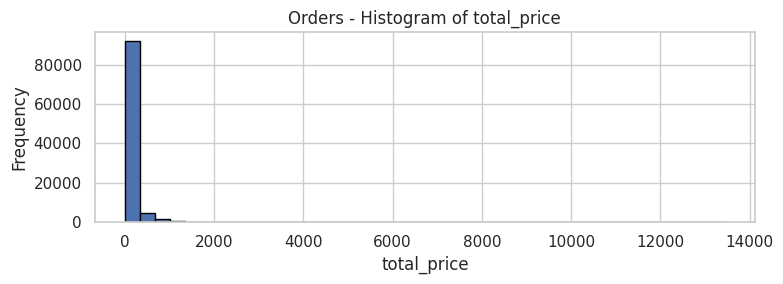

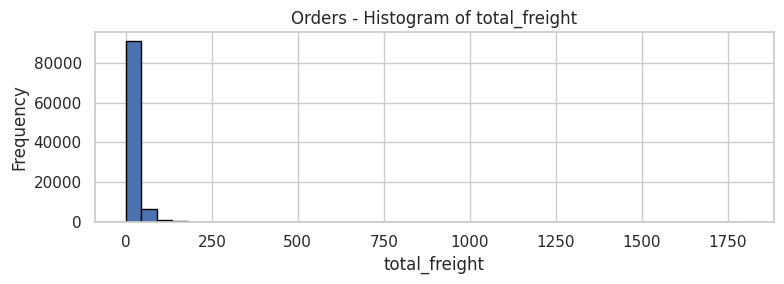

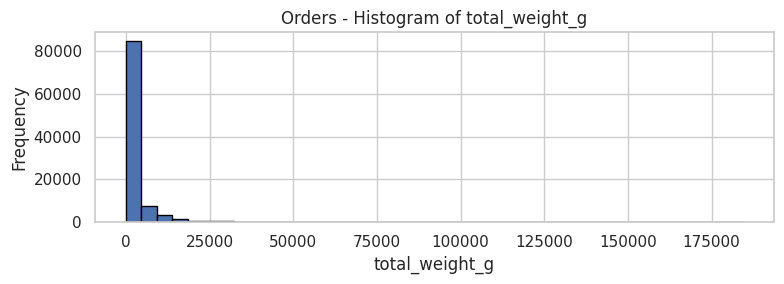

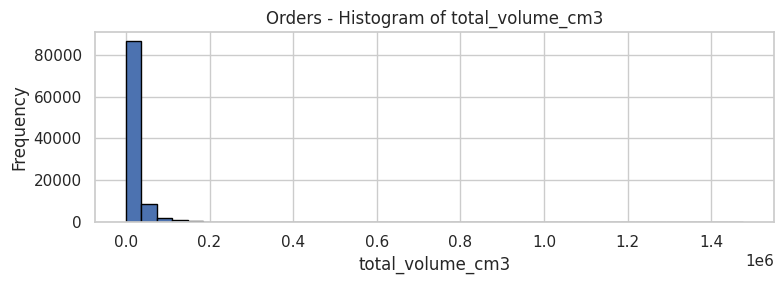

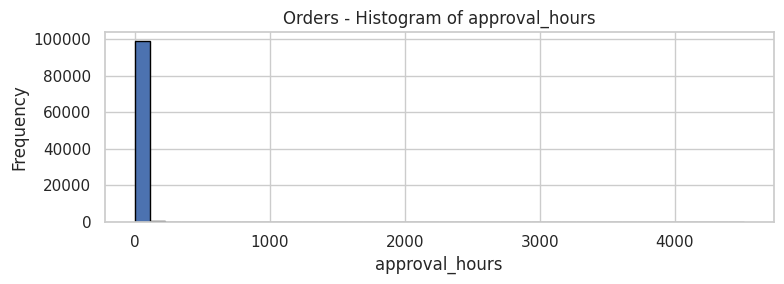

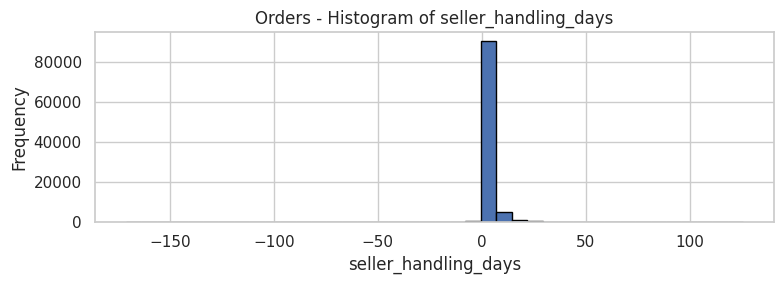

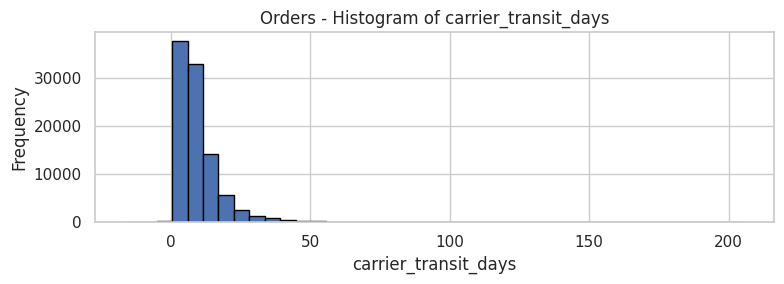

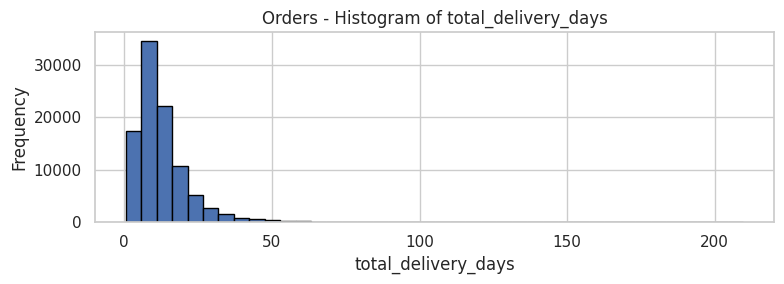

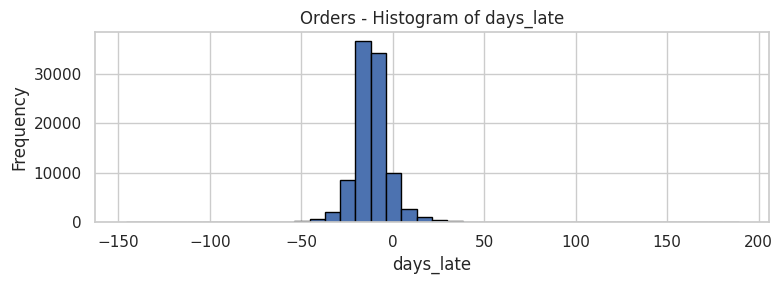

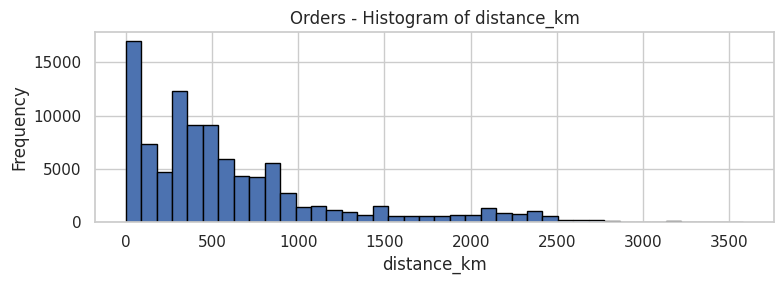

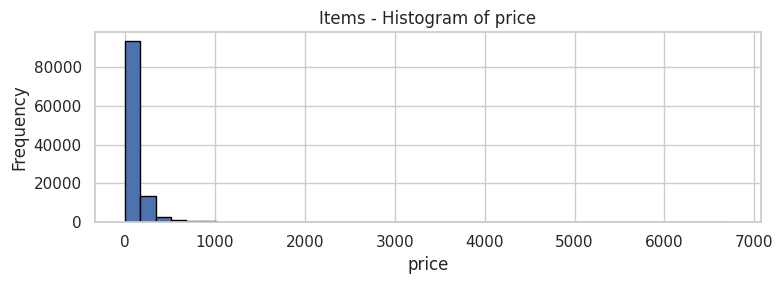

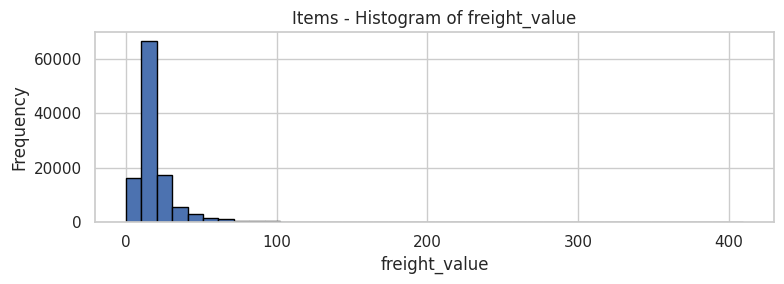

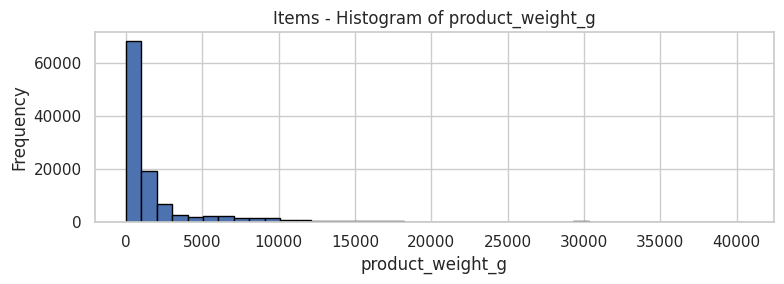

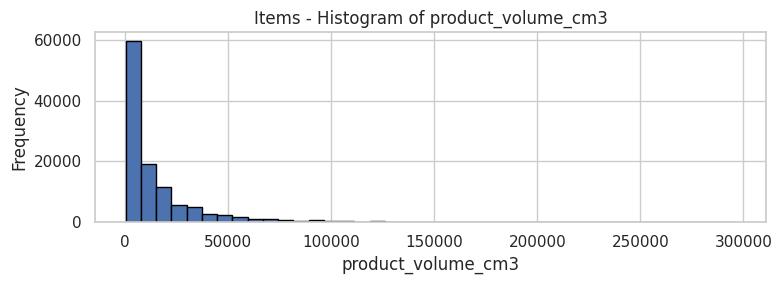

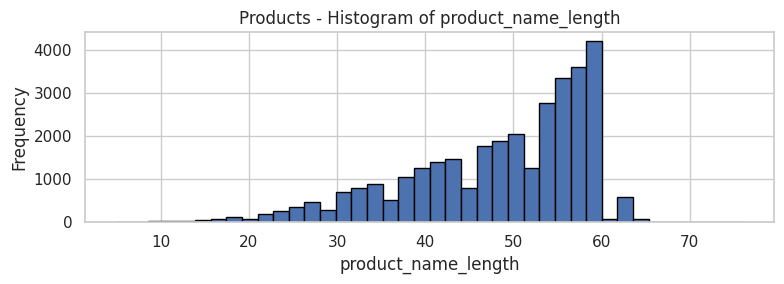

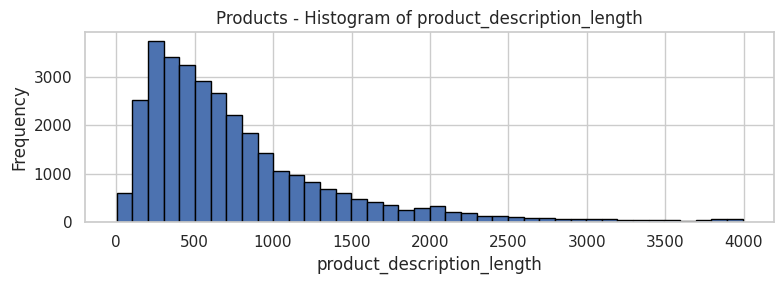

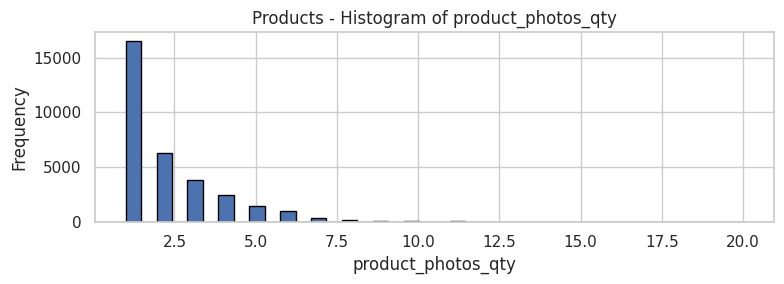

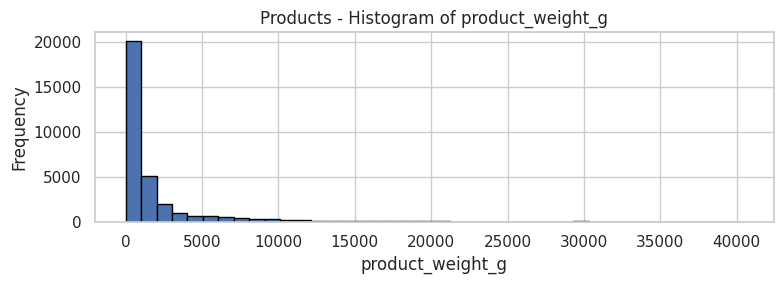

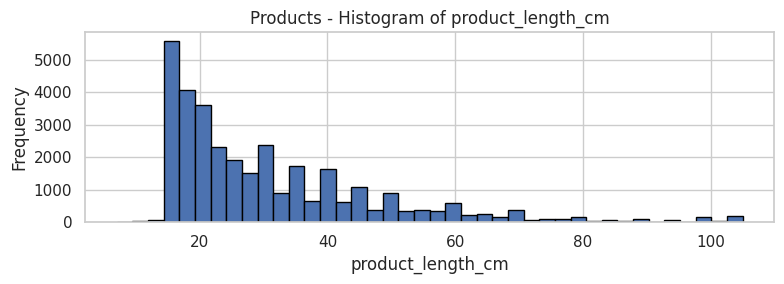

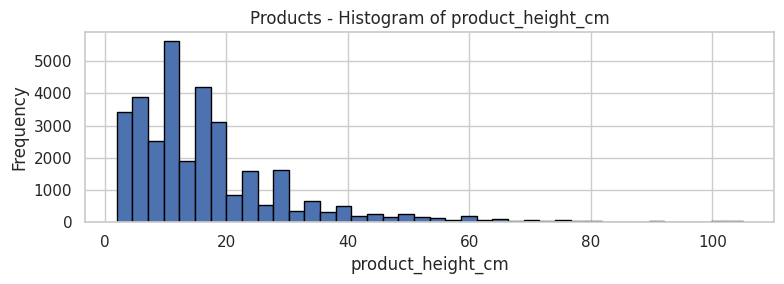

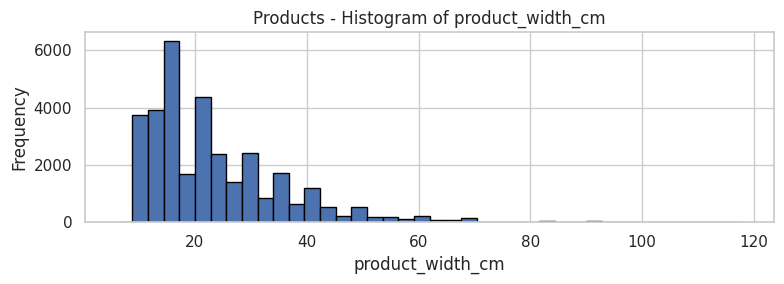

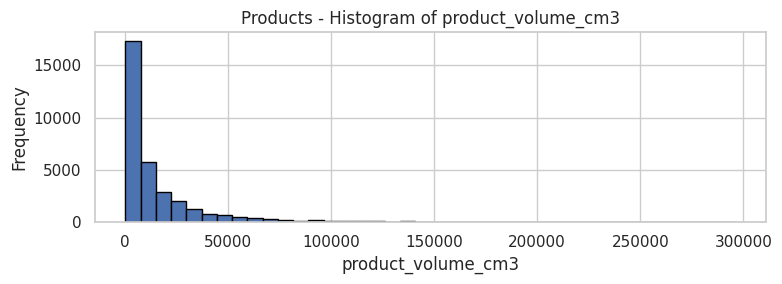

In [8]:
# Plot a histogram for each selected numerical variable
for dataset_name, data in outlier_datasets.items():
    for column in data.columns:
        values = data[column].dropna()

        if len(values) == 0:
            continue

        plt.figure(figsize=(8, 3))
        plt.hist(values, bins=40, edgecolor="black")
        plt.title(f"{dataset_name} - Histogram of {column}")
        plt.xlabel(column)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

### 2.6 Scatter Plot

A scatter plot examines two numerical variables together. It can reveal an observation that is unusual because of its combination of values, even when neither variable looks unusual on its own.

The plots below use relevant pairs of variables from the order, item and product datasets. A sample is used only for plotting when a dataset contains many rows; the underlying data is not modified.

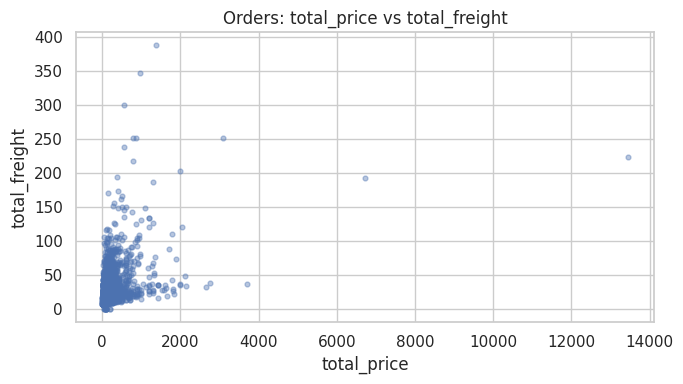

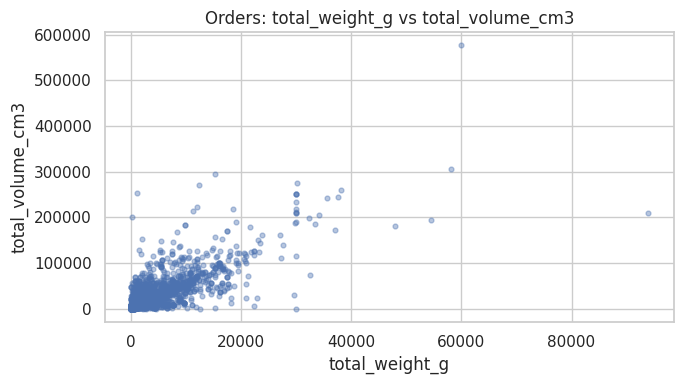

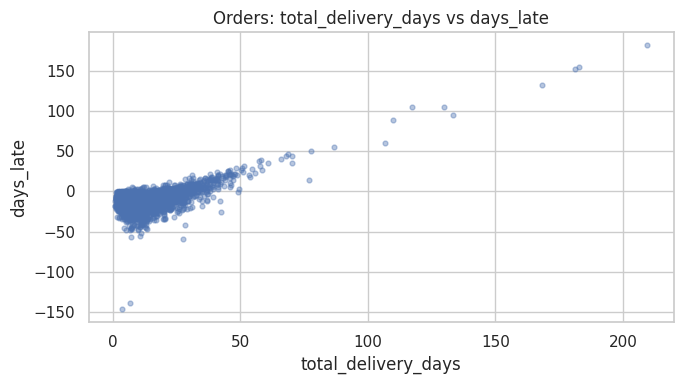

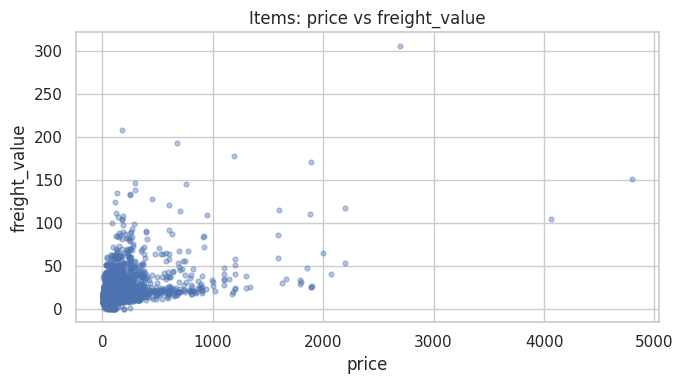

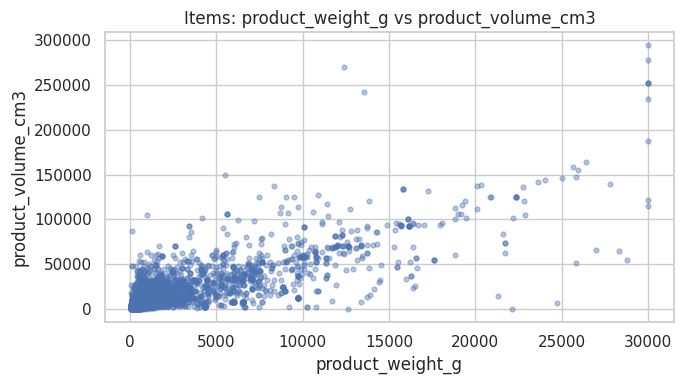

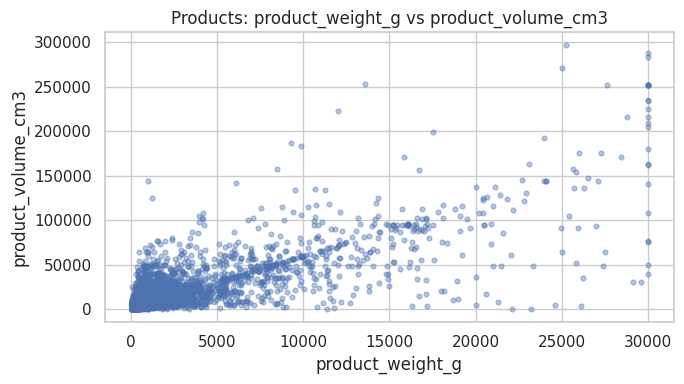

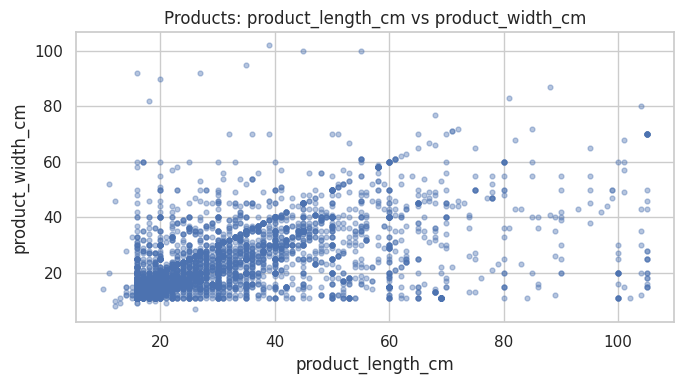

In [9]:
# Variable pairs selected for scatter-plot inspection
scatter_pairs = {
    "Orders": [
        ("total_price", "total_freight"),
        ("total_weight_g", "total_volume_cm3"),
        ("total_delivery_days", "days_late")
    ],
    "Items": [
        ("price", "freight_value"),
        ("product_weight_g", "product_volume_cm3")
    ],
    "Products": [
        ("product_weight_g", "product_volume_cm3"),
        ("product_length_cm", "product_width_cm")
    ]
}

for dataset_name, pairs in scatter_pairs.items():
    data = outlier_datasets[dataset_name]

    for x_column, y_column in pairs:
        if x_column not in data.columns or y_column not in data.columns:
            continue

        plot_data = data[[x_column, y_column]].dropna()

        if plot_data.empty:
            continue

        # Limit plotted points for readability; this does not affect other analyses.
        if len(plot_data) > 5000:
            plot_data = plot_data.sample(5000, random_state=42)

        plt.figure(figsize=(7, 4))
        plt.scatter(
            plot_data[x_column],
            plot_data[y_column],
            alpha=0.4,
            s=12
        )
        plt.title(f"{dataset_name}: {x_column} vs {y_column}")
        plt.xlabel(x_column)
        plt.ylabel(y_column)
        plt.tight_layout()
        plt.show()

### 2.7 Compare IQR and Z-score Results

The IQR and Z-score methods are compared variable by variable. Their counts may differ because IQR uses quartiles, while Z-score uses the mean and standard deviation.

The boxplot, histogram and scatter plot are visual inspection methods; IQR and Z-score provide numerical rules for flagging observations.

In [10]:
univariate_comparison = []

for dataset_name in outlier_datasets:
    for column in outlier_datasets[dataset_name].columns:
        univariate_comparison.append({
            "Dataset": dataset_name,
            "Variable": column,
            "IQR": int(iqr_flags[dataset_name][column].sum()),
            "Z-score": int(zscore_flags[dataset_name][column].sum())
        })

univariate_comparison = pd.DataFrame(univariate_comparison)
display(univariate_comparison)

,Dataset,Variable,IQR,Z-score
0,Orders,total_price,7913,1709
1,Orders,total_freight,9941,1581
2,Orders,total_weight_g,13804,1962
3,Orders,total_volume_cm3,9164,1706
4,Orders,approval_hours,9141,1095
5,Orders,seller_handling_days,5660,1871
6,Orders,carrier_transit_days,5071,1581
7,Orders,total_delivery_days,4899,1571
8,Orders,days_late,4875,1333
9,Orders,distance_km,7622,1564


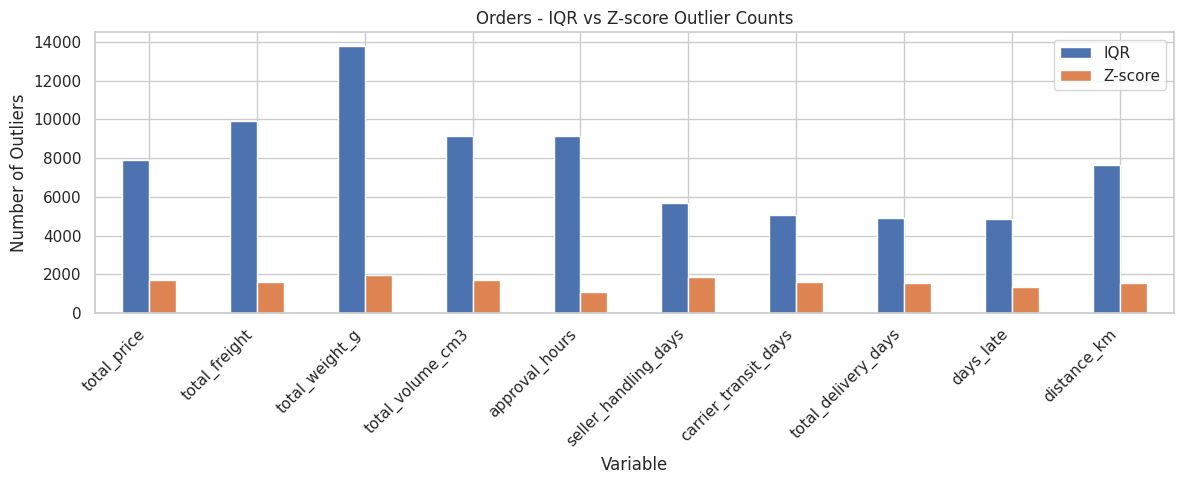

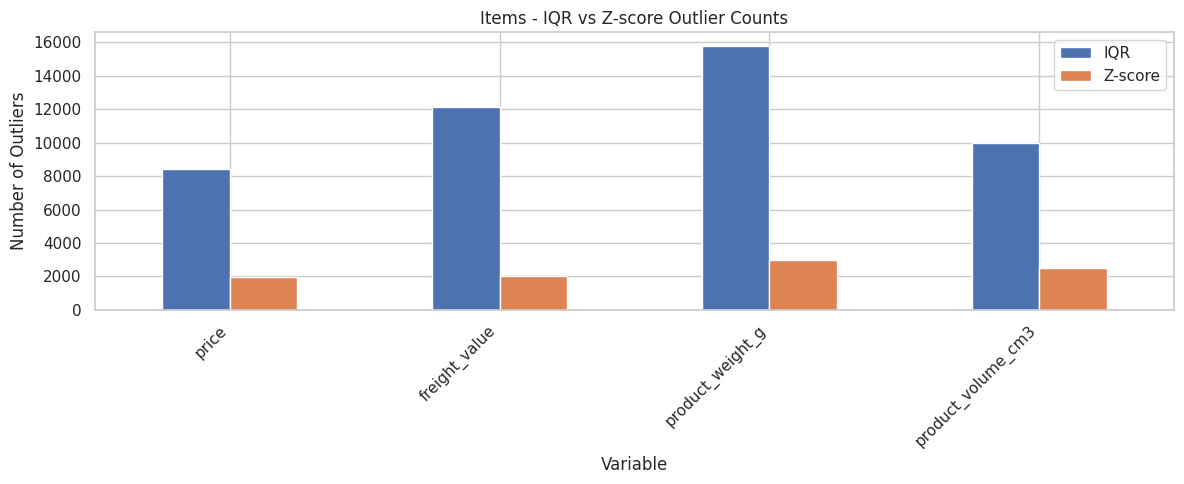

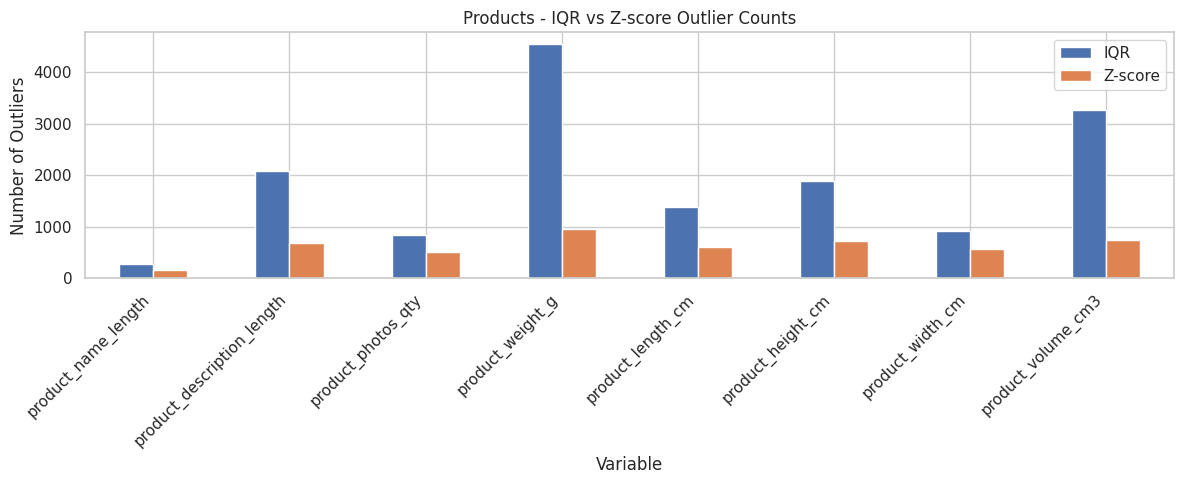

In [11]:
# Plot comparison of IQR and Z-score outlier counts
for dataset_name in outlier_datasets:
    plot_data = univariate_comparison[
        univariate_comparison["Dataset"] == dataset_name
    ].set_index("Variable")[["IQR", "Z-score"]]

    plot_data.plot(kind="bar", figsize=(12, 5))
    plt.title(f"{dataset_name} - IQR vs Z-score Outlier Counts")
    plt.ylabel("Number of Outliers")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### 2.8 Overall Observations – Outlier Detection

1. **IQR results:** The largest count was for `product_weight_g` in the Items dataset (15,807), followed by `total_weight_g` in Orders (13,804) and `freight_value` in Items (12,134).
2. **Z-score results:** Counts were lower than IQR counts for every selected variable. For example, Items `product_weight_g` had 2,955 Z-score flags compared with 15,807 IQR flags.
3. **Distribution shape:** The histograms and skewness values show that several transaction variables are strongly right-skewed, so Z-score results should be interpreted cautiously.
4. **Scatter plots:** These help inspect unusual combinations such as order weight versus volume and price versus freight; they are visual checks rather than automatic outlier counts.

**Conclusion:** IQR, Z-score and the plots identify potential unusual observations, not necessarily errors. Genuine high-value, heavy or delayed orders may be important business cases and should not be removed without checking their context.

## 3. Outlier Handling and Sensitivity Analysis

### Purpose

After detecting outliers, different handling approaches are compared to understand their influence on statistical summaries and distributions.

The following approaches are examined:

1. **Original data:** Retains all observations.
2. **Winsorization:** Caps values below the 1st percentile and above the 99th percentile.
3. **Log transformation:** Applies `log1p` to non-negative variables to reduce right skewness.
4. **Outlier removal:** Removes observations outside the IQR fences for the variable being studied.

The analysis focuses on selected order-level and item-level variables. Outliers are not automatically deleted from the original datasets.

### 3.1 Select Variables for Sensitivity Analysis

The selected variables include order price, freight charges, delivery duration, lateness, distance, product weight and product volume. Negative values are retained in the original and Winsorized data; log transformation is applied only to non-negative variables.

In [12]:
sensitivity_candidates = {
    "Orders": (
        master_orders,
        ["total_price", "total_freight", "total_delivery_days",
         "days_late", "distance_km"]
    ),
    "Items": (
        cleaned_items,
        ["price", "freight_value", "product_weight_g",
         "product_volume_cm3"]
    )
}

sensitivity_data = {}

for name, (data, candidates) in sensitivity_candidates.items():
    columns = [c for c in candidates if c in data.columns]
    sensitivity_data[name] = data[columns].apply(
        pd.to_numeric, errors="coerce"
    )

for name, data in sensitivity_data.items():
    print(name, "selected variables:", data.columns.tolist())

Orders selected variables: ['total_price', 'total_freight', 'total_delivery_days', 'days_late', 'distance_km']
Items selected variables: ['price', 'freight_value', 'product_weight_g', 'product_volume_cm3']


### 3.2 Winsorization (1st and 99th Percentiles)

Winsorization caps extreme observations instead of deleting them. Values below the 1st percentile are replaced with the 1st percentile, and values above the 99th percentile are replaced with the 99th percentile.

In [13]:
winsorized_data = {}

for dataset_name, data in sensitivity_data.items():
    winsorized = data.copy()

    for column in data.columns:
        lower = data[column].quantile(0.01)
        upper = data[column].quantile(0.99)
        winsorized[column] = data[column].clip(
            lower=lower, upper=upper
        )

    winsorized_data[dataset_name] = winsorized

    print("\n", dataset_name, "- Winsorization limits")
    for column in data.columns:
        print(
            column,
            "| 1st percentile:", round(data[column].quantile(0.01), 3),
            "| 99th percentile:", round(data[column].quantile(0.99), 3)
        )


 Orders - Winsorization limits
total_price | 1st percentile: 11.976 | 99th percentile: 998.9
total_freight | 1st percentile: 7.39 | 99th percentile: 104.984
total_delivery_days | 1st percentile: 1.825 | 99th percentile: 46.05
days_late | 1st percentile: -35.154 | 99th percentile: 18.939
distance_km | 1st percentile: 5.745 | 99th percentile: 2482.881

 Items - Winsorization limits
price | 1st percentile: 9.99 | 99th percentile: 890.0
freight_value | 1st percentile: 4.42 | 99th percentile: 84.52
product_weight_g | 1st percentile: 75.0 | 99th percentile: 18250.0
product_volume_cm3 | 1st percentile: 352.0 | 99th percentile: 112284.12


### 3.3 Log Transformation

The `log1p` transformation is:

\[
y = \log(1+x)
\]

It reduces the influence of large positive values. It is applied only when all non-missing observations in a variable are non-negative. Variables such as `days_late` may contain negative values and are therefore not log-transformed in this section.

In [14]:
log_transformed_data = {}

for dataset_name, data in sensitivity_data.items():
    transformed = pd.DataFrame(index=data.index)

    for column in data.columns:
        values = data[column]

        if (values.dropna() >= 0).all():
            transformed[column] = np.log1p(values)
        else:
            transformed[column] = np.nan

    log_transformed_data[dataset_name] = transformed

    print("\n", dataset_name)
    for column in data.columns:
        if transformed[column].notna().any():
            print(
                column,
                "| Original skewness:", round(data[column].skew(), 4),
                "| Log skewness:", round(transformed[column].skew(), 4)
            )
        else:
            print(column, ": log transformation skipped (negative values present).")


 Orders
total_price | Original skewness: 9.7277 | Log skewness: 0.2881
total_freight | Original skewness: 12.0527 | Log skewness: 0.4707
total_delivery_days | Original skewness: 3.8328 | Log skewness: 0.0353
days_late : log transformation skipped (negative values present).
distance_km | Original skewness: 1.6533 | Log skewness: -1.0395

 Items
price | Original skewness: 7.9232 | Log skewness: 0.2935
freight_value | Original skewness: 5.6399 | Log skewness: 0.0011
product_weight_g | Original skewness: 3.5987 | Log skewness: 0.4529
product_volume_cm3 | Original skewness: 4.076 | Log skewness: 0.0324


### 3.4 Outlier Removal Using IQR

For sensitivity analysis, outliers are removed one variable at a time. This makes it possible to compare the original distribution of a variable with the distribution after removing observations outside that variable's IQR fences.



In [15]:
iqr_removed_data = {}

for dataset_name, data in sensitivity_data.items():
    removed_dataset = {}

    for column in data.columns:
        values = data[column].dropna()

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr_value = q3 - q1

        lower = q1 - 1.5 * iqr_value
        upper = q3 + 1.5 * iqr_value

        filtered_values = values[
            (values >= lower) & (values <= upper)
        ]

        removed_dataset[column] = filtered_values

    iqr_removed_data[dataset_name] = removed_dataset

    print("\n", dataset_name, "- IQR Removal")
    for column, filtered_values in removed_dataset.items():
        original_count = data[column].notna().sum()
        removed_count = original_count - len(filtered_values)
        print(
            column,
            "| Original:", original_count,
            "| Remaining:", len(filtered_values),
            "| Removed:", removed_count
        )


 Orders - IQR Removal
total_price | Original: 98666 | Remaining: 90753 | Removed: 7913
total_freight | Original: 98666 | Remaining: 88725 | Removed: 9941
total_delivery_days | Original: 96476 | Remaining: 91577 | Removed: 4899
days_late | Original: 96476 | Remaining: 91601 | Removed: 4875
distance_km | Original: 98174 | Remaining: 90552 | Removed: 7622

 Items - IQR Removal
price | Original: 112650 | Remaining: 104223 | Removed: 8427
freight_value | Original: 112650 | Remaining: 100516 | Removed: 12134
product_weight_g | Original: 112632 | Remaining: 96825 | Removed: 15807
product_volume_cm3 | Original: 112632 | Remaining: 102628 | Removed: 10004


### 3.5 Compare Statistical Summaries Before and After Handling

Mean, median, standard deviation and skewness are compared to understand how each treatment changes the distribution. The comparison is performed separately for each variable.

In [16]:
sensitivity_results = []

for dataset_name, data in sensitivity_data.items():
    for column in data.columns:
        original_values = data[column].dropna()
        winsor_values = winsorized_data[dataset_name][column].dropna()
        log_values = log_transformed_data[dataset_name][column].dropna()
        removed_values = iqr_removed_data[dataset_name][column]

        comparison_sets = {
            "Original": original_values,
            "Winsorized": winsor_values,
            "Log Transformed": log_values,
            "IQR Outliers Removed": removed_values
        }

        for method, values in comparison_sets.items():
            status = "Available"
            if method == "Log Transformed" and len(values) == 0:
                status = "Skipped: variable contains negative values"

            sensitivity_results.append({
                "Dataset": dataset_name,
                "Variable": column,
                "Method": method,
                "Status": status,
                "Count": len(values),
                "Mean": values.mean(),
                "Median": values.median(),
                "Standard Deviation": values.std(),
                "Skewness": values.skew()
            })

sensitivity_summary = pd.DataFrame(sensitivity_results)
display(sensitivity_summary.round(4))

,Dataset,Variable,Method,Status,Count,Mean,Median,Standard Deviation,Skewness
0,Orders,total_price,Original,Available,98666,137.7541,86.9000,210.6451,9.7277
1,Orders,total_price,Winsorized,Available,98666,131.8215,86.9000,155.9535,3.2761
2,Orders,total_price,Log Transformed,Available,98666,4.4610,4.4762,0.9187,0.2881
3,Orders,total_price,IQR Outliers Removed,Available,90753,94.4392,79.0000,66.0580,1.0347
4,Orders,total_freight,Original,Available,98666,22.8236,17.1700,21.6509,12.0527
5,Orders,total_freight,Winsorized,Available,98666,22.2846,17.1700,16.3084,2.7465
6,Orders,total_freight,Log Transformed,Available,98666,2.9876,2.8998,0.5567,0.4707
7,Orders,total_freight,IQR Outliers Removed,Available,88725,17.7864,16.3400,7.1577,0.9184
8,Orders,total_delivery_days,Original,Available,96476,12.5587,10.2178,9.5465,3.8328
9,Orders,total_delivery_days,Winsorized,Available,96476,12.3968,10.2178,8.4078,1.6235


### 3.6 Visual Comparison of Original and Winsorized Distributions

The histograms below compare the original and Winsorized distributions. Winsorization retains the number of observations but caps extreme values at the selected percentile limits.

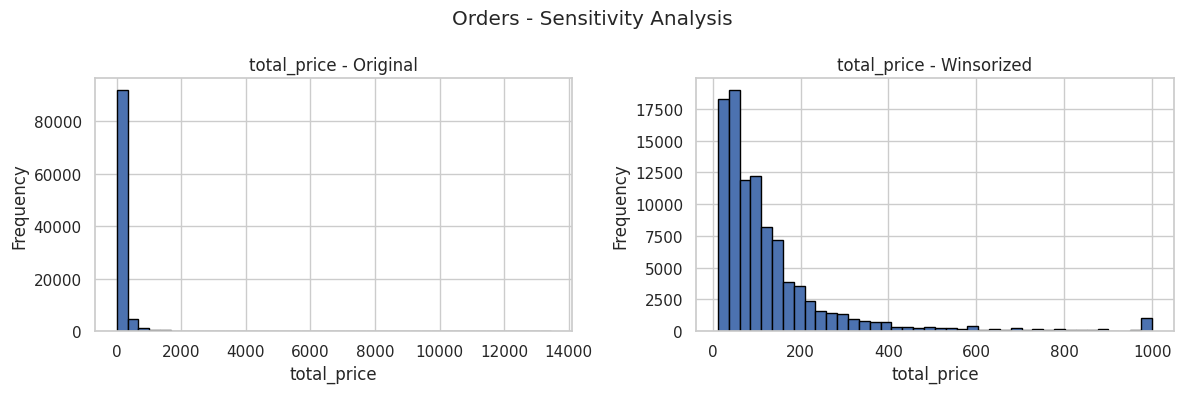

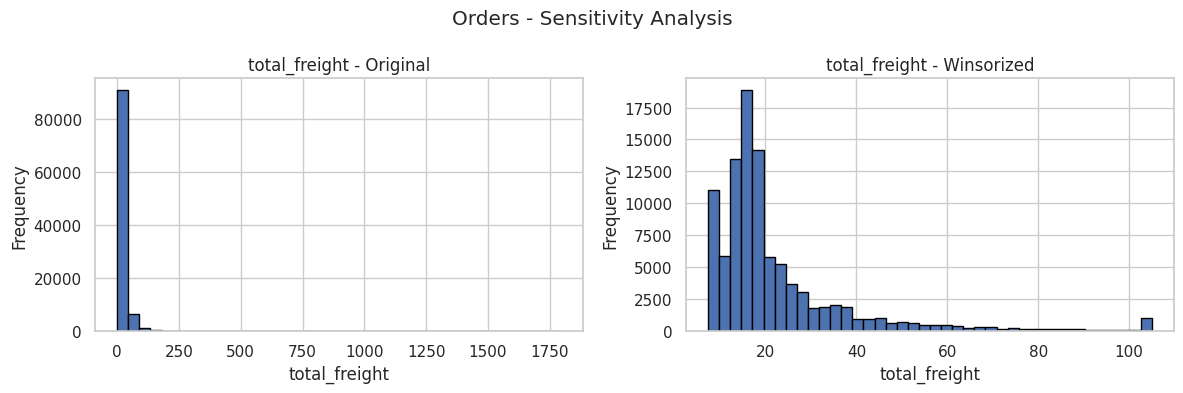

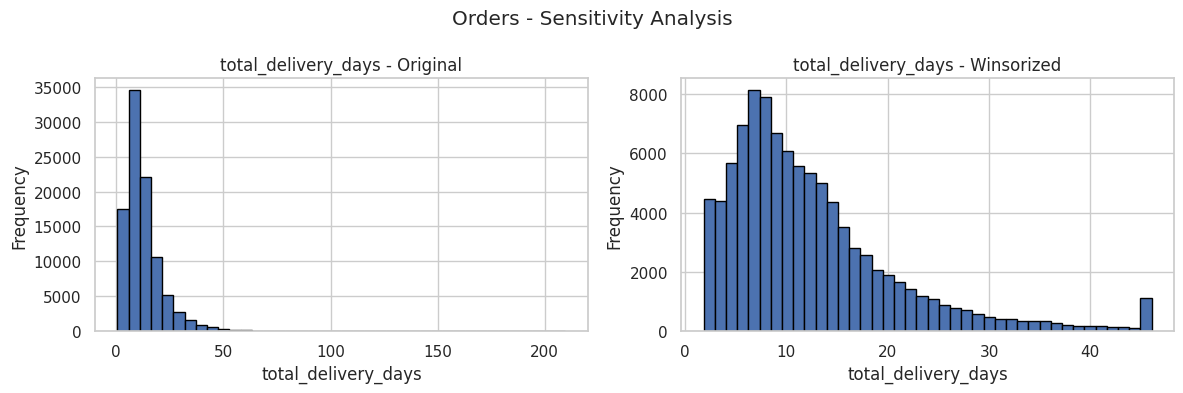

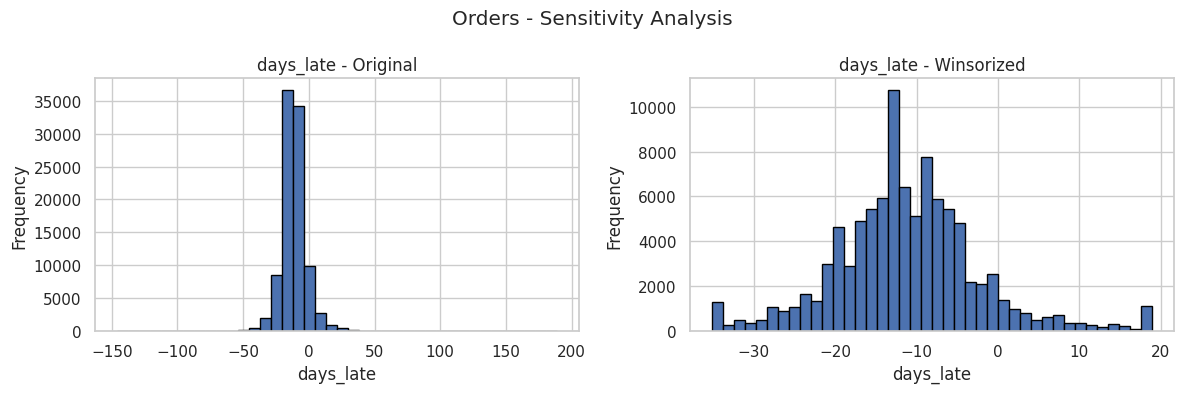

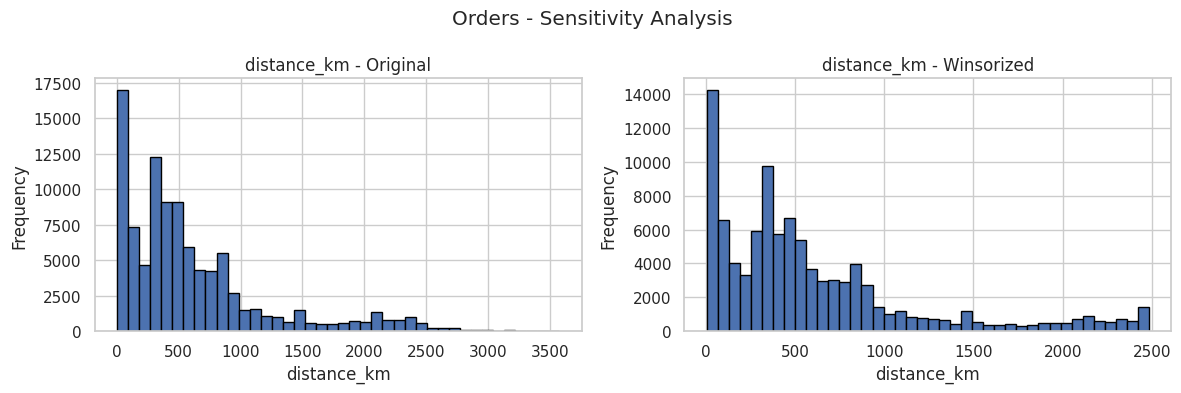

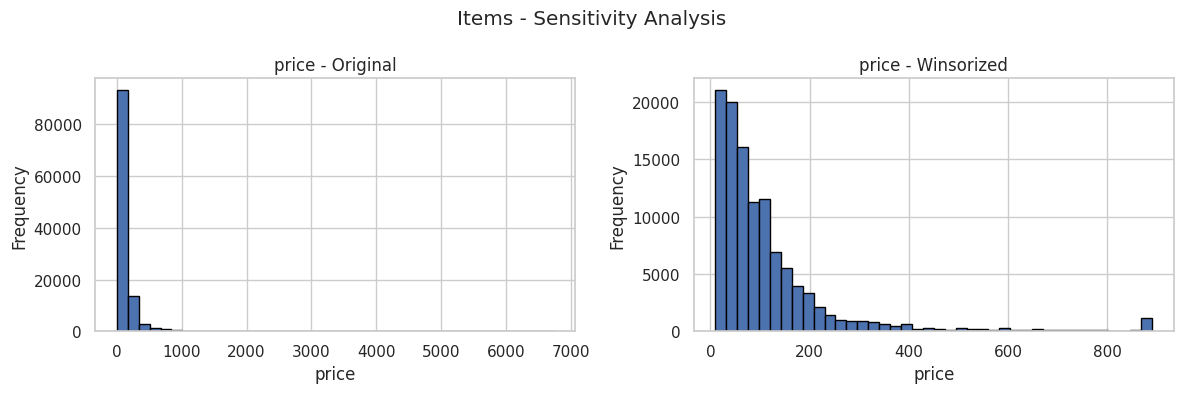

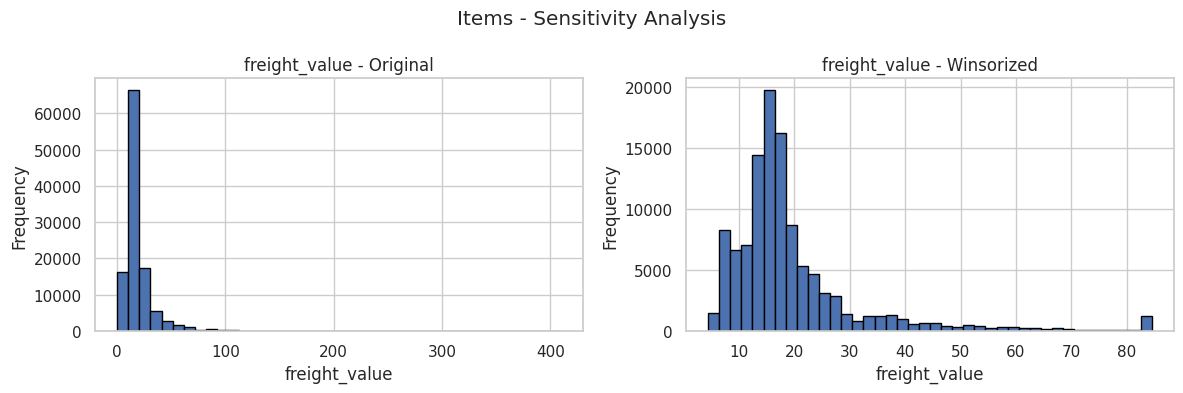

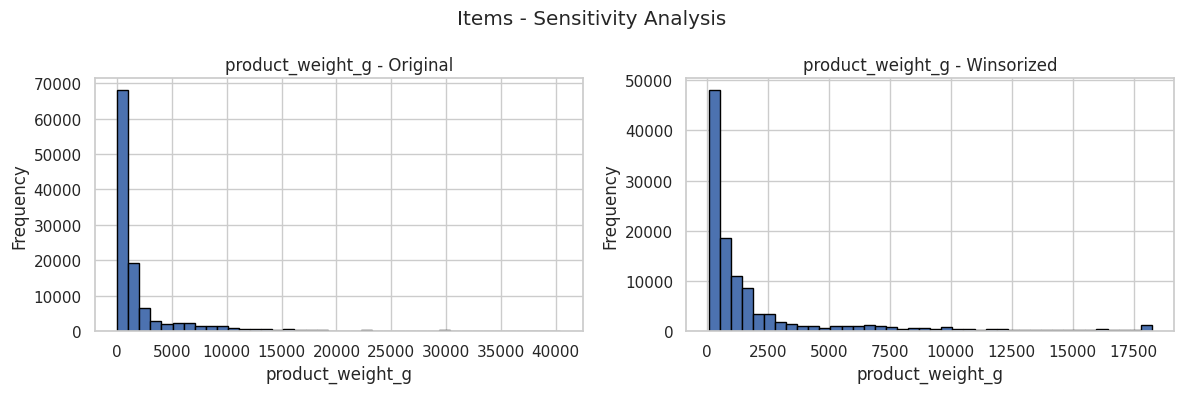

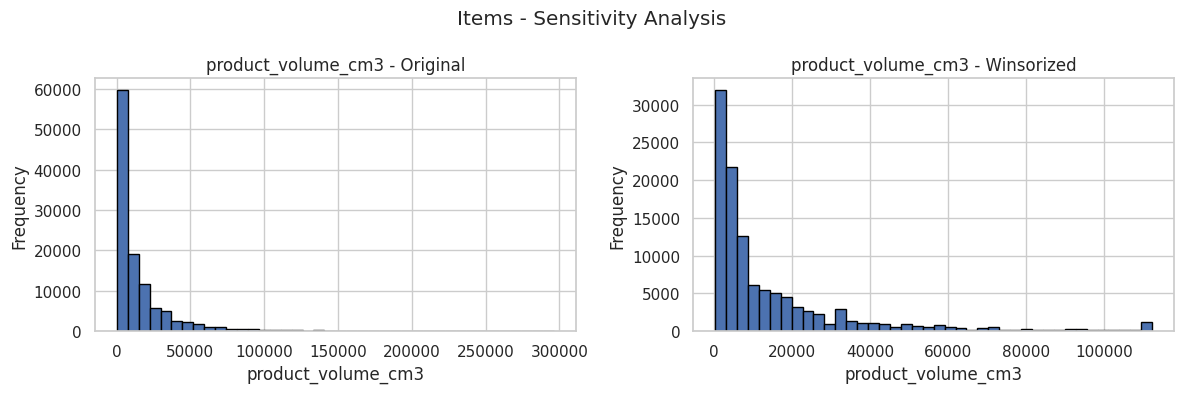

In [17]:
for dataset_name, data in sensitivity_data.items():
    for column in data.columns:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        original_values = data[column].dropna()
        winsor_values = winsorized_data[dataset_name][column].dropna()

        axes[0].hist(original_values, bins=40, edgecolor="black")
        axes[0].set_title(f"{column} - Original")
        axes[0].set_xlabel(column)
        axes[0].set_ylabel("Frequency")

        axes[1].hist(winsor_values, bins=40, edgecolor="black")
        axes[1].set_title(f"{column} - Winsorized")
        axes[1].set_xlabel(column)
        axes[1].set_ylabel("Frequency")

        fig.suptitle(f"{dataset_name} - Sensitivity Analysis")
        plt.tight_layout()
        plt.show()

### 3.7 Observations – Outlier Handling and Sensitivity Analysis

1. **Winsorization:** Capping values at the 1st and 99th percentiles reduced the standard deviation for all selected variables while retaining the same number of non-missing observations.
2. **Mean and median:** The mean decreased after Winsorization, while the median remained unchanged in the displayed comparisons. This shows that the mean is more sensitive to extreme values.
3. **Log transformation:** Positive skewness decreased for most non-negative variables. For example, `total_freight` skewness decreased from 12.0527 to 0.4707, and `total_delivery_days` decreased from 3.8328 to 0.0353. For `distance_km`, skewness changed from 1.6533 to -1.0395, so the transformation reduced its magnitude but made the distribution negatively skewed. Log transformation was skipped for `days_late` because it contains negative values.
4. **IQR removal:** The highest number of values removed was for Items `product_weight_g` (15,807 of 112,632 valid values), followed by Items `freight_value` (12,134 of 112,650).
5. **Interpretation:** IQR removal was evaluated one variable at a time. These counts do not mean that those rows were permanently deleted from the original datasets.

**Conclusion:** Winsorization reduces the influence of extreme values without reducing the sample count. Log transformation can reduce skewness, but it is not suitable for variables containing negative values and may over-correct some distributions. IQR removal can exclude many observations, so it should be treated as a sensitivity analysis rather than automatic cleaning.

## 4. Missing Value Analysis

### Purpose

Missing values occur when a feature has no recorded value. Missing product dimensions or weights may affect freight analysis and later machine learning models.

This section identifies missing values in the processed datasets and studies whether missing review comments are associated with customer ratings and delivery lateness.

### 4.1 Missing Value Count and Percentage

For each dataset, the number and percentage of missing values are calculated column by column.

In [18]:
missing_tables = {}

for dataset_name, data in datasets.items():
    missing_table = pd.DataFrame({
        "Missing Count": data.isnull().sum(),
        "Missing Percentage": data.isnull().mean() * 100
    }).sort_values("Missing Percentage", ascending=False)

    missing_tables[dataset_name] = missing_table

    print("\n", dataset_name.upper(), "- Missing Value Summary")
    display(missing_table[missing_table["Missing Count"] > 0].round(2))


 MASTER_ORDERS - Missing Value Summary


,Missing Count,Missing Percentage
review_comment_title,87890,88.38
review_comment_message,58664,58.99
carrier_transit_days,2966,2.98
total_delivery_days,2965,2.98
lateness_bucket,2965,2.98
is_late,2965,2.98
days_late,2965,2.98
order_delivered_customer_date,2965,2.98
seller_handling_days,1797,1.81
order_delivered_carrier_date,1783,1.79



 MASTER_SELLERS - Missing Value Summary


,Missing Count,Missing Percentage
avg_transit_days,125,4.04
late_rate,125,4.04
avg_days_late,125,4.04
avg_delivery_days,125,4.04
median_handling_days,118,3.81
avg_handling_days,118,3.81
avg_distance_km,5,0.16
avg_review_score,5,0.16
low_review_rate,5,0.16



 CLEANED_PRODUCTS - Missing Value Summary


,Missing Count,Missing Percentage
product_category_name,610,1.85
product_name_length,610,1.85
product_description_length,610,1.85
product_photos_qty,610,1.85
product_height_cm,2,0.01
product_weight_g,2,0.01
product_length_cm,2,0.01
product_volume_cm3,2,0.01
product_width_cm,2,0.01



 CLEANED_ITEMS - Missing Value Summary


,Missing Count,Missing Percentage
product_volume_cm3,18,0.02
product_weight_g,18,0.02



 CLEANED_REVIEWS - Missing Value Summary


,Missing Count,Missing Percentage
review_comment_title,87122,88.29
review_comment_message,57896,58.67


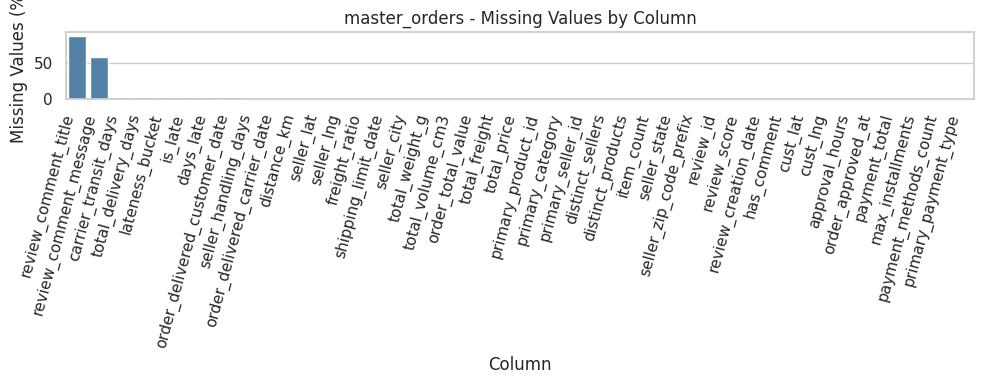

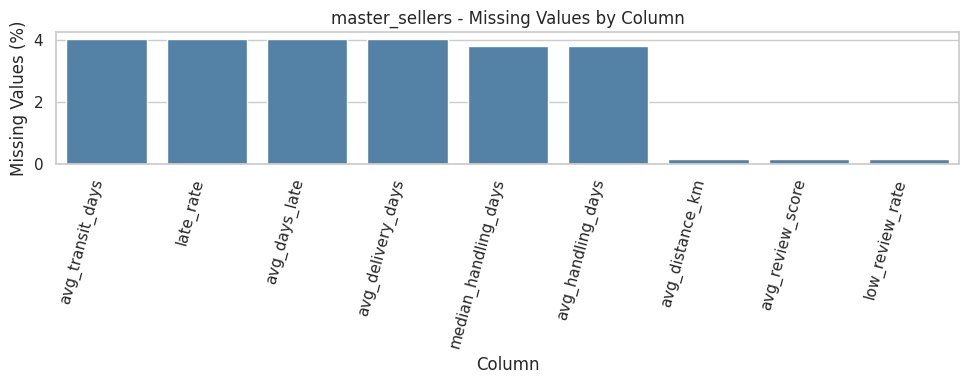

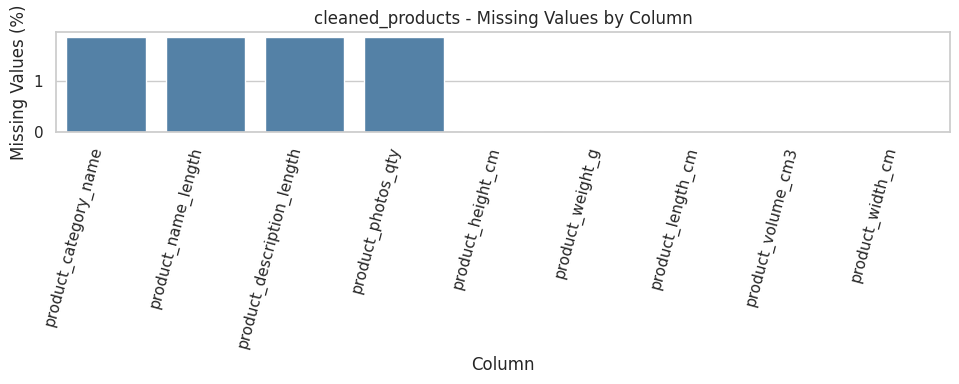

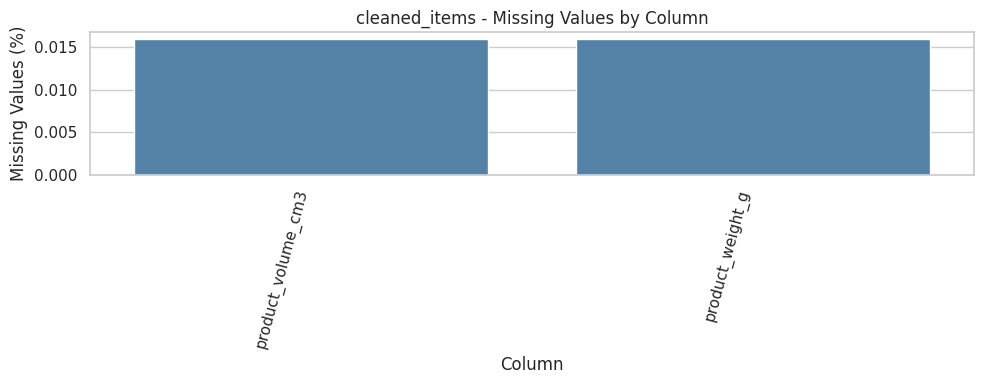

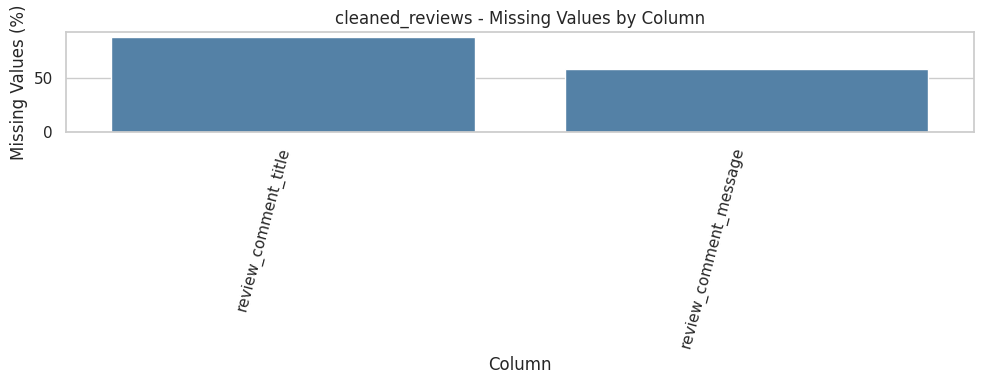

In [19]:
# Visualize missing-value percentages for each dataset
for dataset_name, missing_table in missing_tables.items():
    plot_table = missing_table[
        missing_table["Missing Percentage"] > 0
    ].sort_values("Missing Percentage", ascending=False)

    if len(plot_table) > 0:
        plt.figure(figsize=(10, 4))
        sns.barplot(
            x=plot_table.index,
            y=plot_table["Missing Percentage"],
            color="steelblue"
        )
        plt.title(f"{dataset_name} - Missing Values by Column")
        plt.ylabel("Missing Values (%)")
        plt.xlabel("Column")
        plt.xticks(rotation=75, ha="right")
        plt.tight_layout()
        plt.show()

### 4.2 Missing Review Comment Analysis

The order-level `master_orders` dataset contains review scores, written-comment availability and delivery-lateness information. A missing comment does not mean that the review score itself is missing.

A binary variable is used:

- `1` = A written comment is available.
- `0` = No written comment is available.

The analysis uses rows with non-missing review score, days late and comment availability, then compares comment availability by review score and delivery-lateness category.

In [20]:

review_analysis = master_orders[
    ["order_id", "review_score", "days_late", "has_comment"]
].copy()


if "has_comment" not in review_analysis.columns:
    review_analysis["has_comment"] = (
        master_orders["review_comment_message"].notna().astype(int)
    )

review_analysis["has_comment"] = pd.to_numeric(
    review_analysis["has_comment"], errors="coerce"
)

review_analysis = review_analysis.dropna(
    subset=["review_score", "days_late", "has_comment"]
)

review_analysis["has_comment"] = (
    review_analysis["has_comment"] > 0
).astype(int)

print("Review analysis shape:", review_analysis.shape)
display(review_analysis.head())
print("\nComment availability:")
display(review_analysis["has_comment"].value_counts())

Review analysis shape: (95830, 4)


,order_id,review_score,days_late,has_comment
0,e481f51cbdc54678b7cc49136f2d6af7,4.0,-7.107488,1
1,53cdb2fc8bc7dce0b6741e2150273451,4.0,-5.355729,1
2,47770eb9100c2d0c44946d9cf07ec65d,5.0,-17.245498,0
3,949d5b44dbf5de918fe9c16f97b45f8a,5.0,-12.980069,1
4,ad21c59c0840e6cb83a9ceb5573f8159,5.0,-9.238171,0



Comment availability:


has_comment
0    56924
1    38906
Name: count, dtype: int64

### 4.3 Comment Availability by Review Score

The percentage of customers who wrote comments is calculated for each review score. This helps determine whether customers giving lower ratings are more likely to explain their experience in writing.

Comment Availability by Review Score


,count,mean,Comment Percentage
review_score,,,
1.0,9355,0.78,77.56
2.0,2919,0.68,67.87
3.0,7917,0.43,43.34
4.0,18895,0.31,31.19
5.0,56744,0.36,35.85


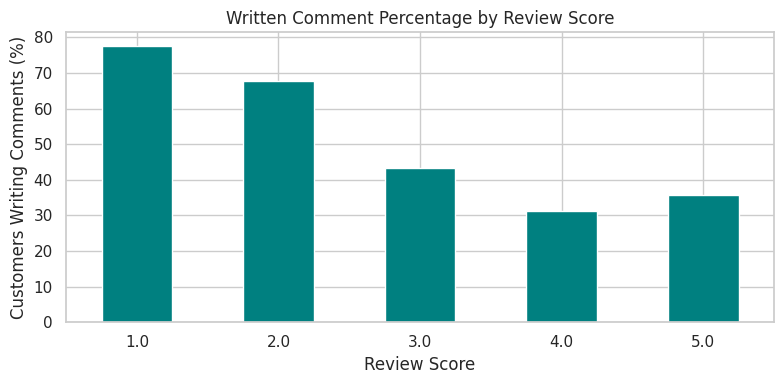

In [21]:
comment_by_score = (
    review_analysis.groupby("review_score")["has_comment"]
    .agg(["count", "mean"])
)

comment_by_score["Comment Percentage"] = (
    comment_by_score["mean"] * 100
)

print("Comment Availability by Review Score")
display(comment_by_score.round(2))

comment_by_score["Comment Percentage"].plot(
    kind="bar", figsize=(8, 4), color="teal"
)
plt.title("Written Comment Percentage by Review Score")
plt.xlabel("Review Score")
plt.ylabel("Customers Writing Comments (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.4 Comment Availability by Delivery Lateness

Orders are grouped into five lateness categories: Early, On Time, 1–3 Days Late, 4–7 Days Late and more than 7 Days Late. The percentage of orders with written comments is compared across these groups.

,count,mean,Comment Percentage
lateness_bucket,,,
Early,86718,0.39,39.34
On Time,1450,0.37,36.62
1-3 Days Late,2636,0.42,42.07
4-7 Days Late,1773,0.58,57.70
>7 Days Late,3253,0.65,65.36


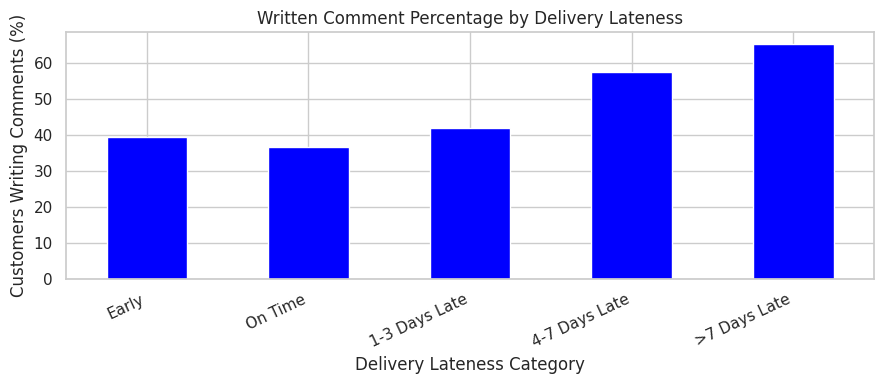

In [22]:
def make_lateness_bucket(days):
    if pd.isna(days):
        return np.nan
    elif days < -1:
        return "Early"
    elif days <= 0:
        return "On Time"
    elif days <= 3:
        return "1-3 Days Late"
    elif days <= 7:
        return "4-7 Days Late"
    else:
        return ">7 Days Late"

lateness_order = [
    "Early", "On Time", "1-3 Days Late",
    "4-7 Days Late", ">7 Days Late"
]

review_analysis["lateness_bucket"] = (
    review_analysis["days_late"].apply(make_lateness_bucket)
)

comment_by_lateness = (
    review_analysis.groupby("lateness_bucket", observed=False)["has_comment"]
    .agg(["count", "mean"])
    .reindex(lateness_order)
)

comment_by_lateness["Comment Percentage"] = (
    comment_by_lateness["mean"] * 100
)

display(comment_by_lateness.round(2))

comment_by_lateness["Comment Percentage"].plot(
    kind="bar", figsize=(9, 4), color="blue"
)
plt.title("Written Comment Percentage by Delivery Lateness")
plt.xlabel("Delivery Lateness Category")
plt.ylabel("Customers Writing Comments (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 4.5 Chi-Square Test: Comment Availability and Delivery Lateness

The Chi-Square Test of Independence checks whether written-comment availability is associated with delivery lateness category.

**Hypotheses**

- **H0:** Comment availability and delivery lateness category are independent.
- **H1:** Comment availability and delivery lateness category are associated.

A significance level of 0.05 is used.

In [23]:
comment_contingency = pd.crosstab(
    review_analysis["lateness_bucket"],
    review_analysis["has_comment"]
).reindex(lateness_order).fillna(0)

comment_contingency.columns = [
    "No Comment" if c == 0 else "Has Comment"
    for c in comment_contingency.columns
]

print("CONTINGENCY TABLE")
display(comment_contingency)

chi2_comment, p_comment, dof_comment, expected_comment = (
    chi2_contingency(comment_contingency)
)

print("\nCHI-SQUARE TEST")
print("----------------")
print("Chi-square statistic:", chi2_comment)
print("Degrees of freedom:", dof_comment)
print("P-value:", p_comment)

if p_comment < 0.05:
    print("Result: Reject H0. Comment availability is significantly associated with delivery lateness category.")
else:
    print("Result: Fail to reject H0. No statistically significant association was found.")

CONTINGENCY TABLE


,No Comment,Has Comment
lateness_bucket,,
Early,52601,34117
On Time,919,531
1-3 Days Late,1527,1109
4-7 Days Late,750,1023
>7 Days Late,1127,2126



CHI-SQUARE TEST
----------------
Chi-square statistic: 1110.3127192541285
Degrees of freedom: 4
P-value: 4.404061025408941e-239
Result: Reject H0. Comment availability is significantly associated with delivery lateness category.


### 4.6 Logistic Regression: Predicting Comment Availability

Logistic Regression is used to examine whether review score and delivery lateness contain information useful for predicting whether a customer wrote a comment.

**Target variable:** `has_comment` (1 = comment available, 0 = no comment)

**Predictor variables:** `review_score` and `days_late`

Rows missing any of these three fields are excluded before modelling. The remaining data is split into training and test sets; numerical predictors are standardized before Logistic Regression is fitted.

In [24]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

X = review_analysis[["review_score", "days_late"]]
y = review_analysis["has_comment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

comment_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

comment_model.fit(X_train, y_train)
y_pred_comment = comment_model.predict(X_test)

print("LOGISTIC REGRESSION - COMMENT AVAILABILITY")
print("------------------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_comment), 4))
print("Precision:", round(precision_score(y_test, y_pred_comment, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_comment, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_comment, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_comment, zero_division=0))

print("Confusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test, y_pred_comment),
    index=["Actual No Comment", "Actual Has Comment"],
    columns=["Predicted No Comment", "Predicted Has Comment"]
))

LOGISTIC REGRESSION - COMMENT AVAILABILITY
------------------------------------------
Accuracy: 0.58
Precision: 0.4821
Recall: 0.4651
F1-score: 0.4735

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.66      0.65     11385
           1       0.48      0.47      0.47      7781

    accuracy                           0.58     19166
   macro avg       0.56      0.56      0.56     19166
weighted avg       0.58      0.58      0.58     19166

Confusion Matrix:


,Predicted No Comment,Predicted Has Comment
Actual No Comment,7498,3887
Actual Has Comment,4162,3619


### 4.7 Observations – Missing Review Comments

1. **Review score:** The comment rate was highest for 1-star reviews (77.56%) and lowest for 4-star reviews (31.19%). The 5-star comment rate was 35.85%.
2. **Delivery lateness:** The comment rate increased for longer delays: 39.34% for early deliveries, 36.62% for on-time deliveries, 42.07% for 1–3 days late, 57.70% for 4–7 days late and 65.36% for delays greater than 7 days.
3. **Chi-square test:** χ² = 1110.31, with 4 degrees of freedom and p = 4.4041 × 10⁻²³⁹. Since p < 0.05, reject H0; comment availability and delivery-lateness category are statistically associated.
4. **Logistic Regression:** Accuracy was 0.58 and F1-score was 0.4735. This indicates limited predictive performance using review score and days late alone.

**Conclusion:** Lower review scores and longer delivery delays are associated with a higher likelihood of a written comment. The Chi-square result shows association, not causation. The Logistic Regression results also show that these two predictors alone do not predict comment availability particularly well.

## 5. Missing Value Imputation Experiment

### Purpose

This section compares the imputation approaches covered in the missing-value lecture:

1. **Mean Imputation:** Fills a numerical missing value with the column mean.
2. **Median Imputation:** Fills a numerical missing value with the column median.
3. **Mode Imputation:** Fills a categorical missing value with its most frequent category.
4. **kNN Imputation:** Uses the values of the most similar rows to estimate a missing value.
5. **Multiple Imputation:** Creates several completed datasets by repeatedly imputing missing values, analyses each dataset, and pools the estimates.

For the numerical product measurements, Mean, Median, kNN and Multiple Imputation are compared using a masking experiment. Mode imputation is demonstrated separately for the categorical product category.

### Why a Masking Experiment is Required

For naturally missing values, the true value is unknown, so its imputation error cannot be calculated directly. Therefore, 15% of known product measurements are artificially hidden. The estimated values are compared with the original values using MAE and RMSE.

Lower MAE and RMSE indicate better estimates for the artificially hidden values.

### 5.1 Select Product Features

The numerical experiment uses product weight, length, height and width. The product category is retained separately for the categorical mode-imputation demonstration.

In [25]:
imputation_features = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

imputation_features = [
    c for c in imputation_features
    if c in cleaned_products.columns
]

category_column = (
    "product_category_name_english"
    if "product_category_name_english" in cleaned_products.columns
    else "product_category_name"
)

if category_column not in cleaned_products.columns:
    raise ValueError("No product category column was found in cleaned_products.")

product_imputation_data = cleaned_products[
    imputation_features
].apply(pd.to_numeric, errors="coerce")

product_categories = cleaned_products[category_column].copy()

print("Numerical features used:", imputation_features)
print("Categorical feature used:", category_column)
print("Product data shape:", product_imputation_data.shape)

print("\nMissing values in numerical features:")
display(product_imputation_data.isnull().sum().to_frame("Missing Count"))

print("\nMissing values in product category:")
print(product_categories.isnull().sum())

Numerical features used: ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
Categorical feature used: product_category_name_english
Product data shape: (32951, 4)

Missing values in numerical features:


,Missing Count
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2



Missing values in product category:
0


### 5.2 Mode Imputation for a Categorical Feature

Mode imputation fills a missing categorical value with the most frequently occurring category. The cleaned product-category column currently has **no naturally missing values**, so there is nothing to fill directly. To demonstrate the lecture method, 15% of known category labels are temporarily masked, then filled using the mode. The original category labels are retained to check how often the mode matches the masked labels.

This categorical demonstration is separate from the numerical MAE/RMSE experiment.

In [26]:
# The cleaned category column has no naturally missing values.
# Artificially mask a sample only to demonstrate how mode imputation works.
category_original = product_categories.copy()
category_masked = category_original.copy()

known_category_indices = category_original.dropna().index
number_of_categories_to_mask = int(0.15 * len(known_category_indices))

category_rng = np.random.default_rng(42)
category_masked_indices = category_rng.choice(
    known_category_indices,
    size=number_of_categories_to_mask,
    replace=False
)

actual_masked_categories = category_original.loc[category_masked_indices].copy()
category_masked.loc[category_masked_indices] = np.nan

mode_imputer = SimpleImputer(strategy="most_frequent")
category_array = mode_imputer.fit_transform(category_masked.to_frame())

category_mode_imputed = pd.Series(
    category_array.ravel(),
    index=category_masked.index,
    name=category_column
)

mode_accuracy = (
    category_mode_imputed.loc[category_masked_indices]
    == actual_masked_categories
).mean()

print("Natural missing category values:", category_original.isna().sum())
print("Artificially masked category values:", len(category_masked_indices))
print("Missing category values after masking:", category_masked.isna().sum())
print("Missing category values after mode imputation:", category_mode_imputed.isna().sum())
print("Most frequent category used:", mode_imputer.statistics_[0])
print("Mode recovery accuracy on masked categories:", round(mode_accuracy, 4))

Natural missing category values: 0
Artificially masked category values: 4942
Missing category values after masking: 4942
Missing category values after mode imputation: 0
Most frequent category used: bed_bath_table
Mode recovery accuracy on masked categories: 0.0945


### 5.3 Artificially Mask 15% of Known Numerical Values

For each numerical feature, 15% of its known observations are randomly selected and replaced with missing values. The original values are stored separately so that the imputed estimates can be compared with the true values.

The four numerical features each have 32,951 rows and 2 naturally missing values. Therefore, each feature has 32,949 known values, and 15% corresponds to 4,942 artificially masked values (rounded down). The same count appears for each feature because the number of known values is equal; the selected row indices are sampled separately for each feature.

A fixed random seed makes the experiment reproducible.

In [27]:
np.random.seed(42)

X_original = product_imputation_data.copy()
X_masked = X_original.copy()

actual_masked_values = {}
masked_indices = {}

for column in imputation_features:
    known_indices = X_original[column].dropna().index
    number_to_mask = int(0.15 * len(known_indices))

    selected_indices = np.random.choice(
        known_indices,
        size=number_to_mask,
        replace=False
    )

    masked_indices[column] = selected_indices
    actual_masked_values[column] = X_original.loc[
        selected_indices, column
    ].copy()

    X_masked.loc[selected_indices, column] = np.nan

print("Missing values before artificial masking:")
display(X_original.isnull().sum().to_frame("Missing Count"))

print("\nMissing values after artificial masking:")
display(X_masked.isnull().sum().to_frame("Missing Count"))

print("\nNumber of artificially masked values:")
for column in imputation_features:
    print(column, ":", len(masked_indices[column]))

Missing values before artificial masking:


,Missing Count
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2



Missing values after artificial masking:


,Missing Count
product_weight_g,4944
product_length_cm,4944
product_height_cm,4944
product_width_cm,4944



Number of artificially masked values:
product_weight_g : 4942
product_length_cm : 4942
product_height_cm : 4942
product_width_cm : 4942


### 5.4 Mean Imputation

Mean imputation replaces each missing numerical value with the mean of that feature.

In [28]:
mean_imputer = SimpleImputer(strategy="mean")

mean_array = mean_imputer.fit_transform(X_masked)

mean_imputed = pd.DataFrame(
    mean_array,
    columns=imputation_features,
    index=X_masked.index
)

print("Mean Imputation - Remaining Missing Values")
display(mean_imputed.isnull().sum().to_frame("Missing Count"))
display(mean_imputed.head())

Mean Imputation - Remaining Missing Values


,Missing Count
product_weight_g,0
product_length_cm,0
product_height_cm,0
product_width_cm,0


,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,225.0,16.0,10.0,14.0
1,1000.0,30.0,18.0,20.0
2,154.0,18.0,9.0,15.0
3,371.0,26.0,4.0,26.0
4,625.0,20.0,17.0,13.0


### 5.5 Median Imputation

Median imputation replaces each missing numerical value with the median of that feature. As discussed in the lecture, the median is less affected by extreme values than the mean.

In [29]:
median_imputer = SimpleImputer(strategy="median")

median_array = median_imputer.fit_transform(X_masked)

median_imputed = pd.DataFrame(
    median_array,
    columns=imputation_features,
    index=X_masked.index
)

print("Median Imputation - Remaining Missing Values")
display(median_imputed.isnull().sum().to_frame("Missing Count"))
display(median_imputed.head())

Median Imputation - Remaining Missing Values


,Missing Count
product_weight_g,0
product_length_cm,0
product_height_cm,0
product_width_cm,0


,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,225.0,16.0,10.0,14.0
1,1000.0,30.0,18.0,20.0
2,154.0,18.0,9.0,15.0
3,371.0,26.0,4.0,26.0
4,625.0,20.0,17.0,13.0


### 5.6 kNN Imputation

kNN imputation finds rows that are similar to the row with a missing value and estimates the gap using their available values. The numerical features are scaled first because product weight is measured in grams while dimensions are measured in centimetres. The values are converted back to their original units after imputation.

In [30]:
# Scale features so that variables with larger numerical ranges
# do not dominate the distance calculation.
knn_scaler = MinMaxScaler()
X_masked_scaled = knn_scaler.fit_transform(X_masked)

knn_imputer = KNNImputer(n_neighbors=5)

knn_imputed_scaled = knn_imputer.fit_transform(X_masked_scaled)

knn_imputed_array = knn_scaler.inverse_transform(
    knn_imputed_scaled
)

knn_imputed = pd.DataFrame(
    knn_imputed_array,
    columns=imputation_features,
    index=X_masked.index
)

print("kNN Imputation - Remaining Missing Values")
display(knn_imputed.isnull().sum().to_frame("Missing Count"))
display(knn_imputed.head())

kNN Imputation - Remaining Missing Values


,Missing Count
product_weight_g,0
product_length_cm,0
product_height_cm,0
product_width_cm,0


,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,225.0,16.0,10.0,14.0
1,1000.0,30.0,18.0,20.0
2,154.0,18.0,9.0,15.0
3,371.0,26.0,4.0,26.0
4,625.0,20.0,17.0,13.0


### 5.7 Multiple Imputation Using Chained Equations (MICE)

Multiple Imputation creates **m different completed datasets**. Each dataset is produced using a different random draw, the analysis is performed across the completed datasets, and the results are pooled.

Here, five completed datasets (m = 5) are generated. `IterativeImputer` performs the chained feature-estimation cycles, while `sample_posterior=True` introduces variation between imputations. For this masking-based prediction comparison, the five imputed estimates are averaged to create one pooled prediction for each masked value.

**Important limitation:** Averaging the five imputed values provides a pooled point estimate for comparing MAE and RMSE. It is not the full inferential multiple-imputation procedure: formal analysis would also pool model estimates and their variances using Rubin's rules.

In [31]:
# Scale the data before chained-equation imputation.
mice_scaler = MinMaxScaler()
X_masked_scaled_for_mice = mice_scaler.fit_transform(X_masked)

m = 5
multiple_imputed_datasets = []

for seed in range(m):
    mice_imputer = IterativeImputer(
        max_iter=10,
        random_state=42 + seed,
        initial_strategy="median",
        sample_posterior=True
    )

    imputed_scaled = mice_imputer.fit_transform(
        X_masked_scaled_for_mice
    )

    imputed_original_scale = mice_scaler.inverse_transform(
        imputed_scaled
    )

    imputed_df = pd.DataFrame(
        imputed_original_scale,
        columns=imputation_features,
        index=X_masked.index
    )

    multiple_imputed_datasets.append(imputed_df)

# Pool the five imputed datasets by averaging their estimates.
multiple_imputed = sum(multiple_imputed_datasets) / m

print(f"Multiple Imputation: {m} completed datasets generated.")
print("Pooled Multiple Imputation - Remaining Missing Values")
display(multiple_imputed.isnull().sum().to_frame("Missing Count"))
display(multiple_imputed.head())

Multiple Imputation: 5 completed datasets generated.
Pooled Multiple Imputation - Remaining Missing Values


,Missing Count
product_weight_g,0
product_length_cm,0
product_height_cm,0
product_width_cm,0


,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,225.0,16.0,10.0,14.0
1,1000.0,30.0,18.0,20.0
2,154.0,18.0,9.0,15.0
3,371.0,26.0,4.0,26.0
4,625.0,20.0,17.0,13.0


### 5.8 Compare Imputation Methods Using MAE and RMSE

Only artificially masked values are evaluated because their original values are known. Naturally missing values are not included in the error calculation.

The numerical experiment compares Mean, Median, kNN and Multiple Imputation (MICE) for each product feature. MAE and RMSE are calculated separately for each feature; compare methods **within the same feature**, because weight is measured in grams while dimensions are measured in centimetres.

In [32]:
imputation_methods = {
    "Mean": mean_imputed,
    "Median": median_imputed,
    "kNN": knn_imputed,
    "Multiple Imputation (MICE)": multiple_imputed
}

imputation_results = []

for column in imputation_features:
    actual_values = actual_masked_values[column]

    for method_name, imputed_data in imputation_methods.items():
        predicted_values = imputed_data.loc[
            actual_values.index, column
        ]

        mae_value = mean_absolute_error(
            actual_values, predicted_values
        )

        rmse_value = np.sqrt(
            mean_squared_error(actual_values, predicted_values)
        )

        imputation_results.append({
            "Feature": column,
            "Method": method_name,
            "MAE": mae_value,
            "RMSE": rmse_value,
            "Number of Masked Values": len(actual_values)
        })

imputation_results_df = pd.DataFrame(imputation_results)

print("IMPUTATION PERFORMANCE COMPARISON")
display(imputation_results_df.round(4))

IMPUTATION PERFORMANCE COMPARISON


,Feature,Method,MAE,RMSE,Number of Masked Values
0,product_weight_g,Mean,2550.8974,4368.1240,4942
1,product_weight_g,Median,1964.9814,4649.8702,4942
2,product_weight_g,kNN,2130.5953,3944.6671,4942
3,product_weight_g,Multiple Imputation (MICE),2300.2253,3523.9477,4942
4,product_length_cm,Mean,12.6504,16.7733,4942
5,product_length_cm,Median,11.9158,17.7406,4942
6,product_length_cm,kNN,11.0223,15.9061,4942
7,product_length_cm,Multiple Imputation (MICE),10.6791,15.0580,4942
8,product_height_cm,Mean,9.6799,13.8870,4942
9,product_height_cm,Median,9.2934,14.5241,4942


### 5.9 Visualize MAE Comparison

The MAE plot compares the average absolute imputation error. A lower value indicates more accurate estimates for the masked observations.

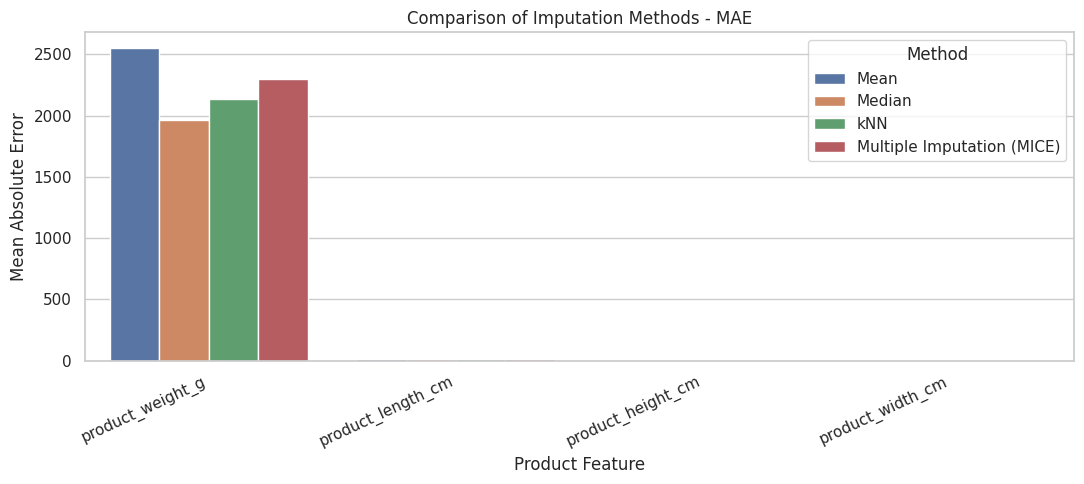

In [33]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=imputation_results_df,
    x="Feature",
    y="MAE",
    hue="Method"
)

plt.title("Comparison of Imputation Methods - MAE")
plt.xlabel("Product Feature")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 5.10 Visualize RMSE Comparison

RMSE gives greater weight to large prediction errors because the errors are squared before averaging. A lower RMSE indicates fewer or smaller large errors.

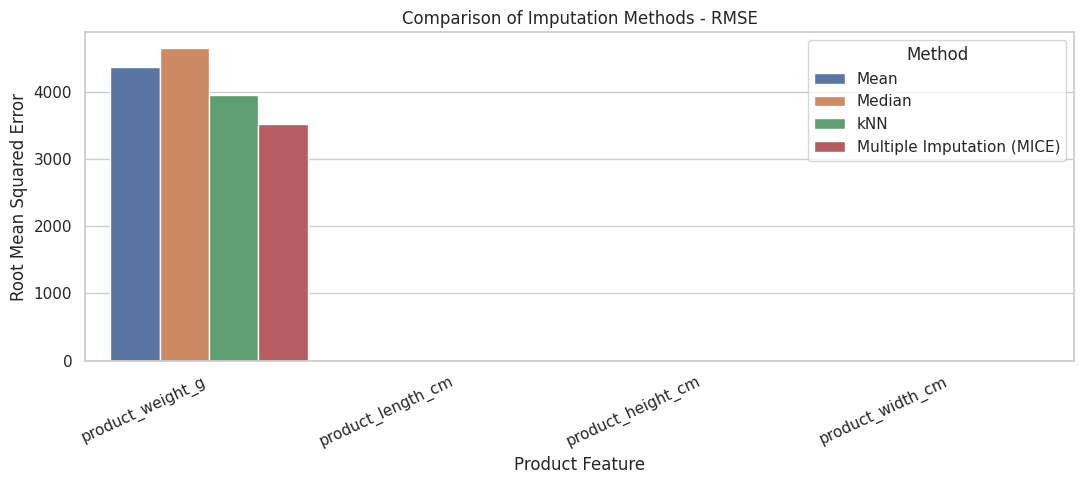

In [34]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=imputation_results_df,
    x="Feature",
    y="RMSE",
    hue="Method"
)

plt.title("Comparison of Imputation Methods - RMSE")
plt.xlabel("Product Feature")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 5.11 Identify the Best Imputation Method for Each Feature

The best method is identified separately for each feature using the lowest MAE. A second table also identifies the best method using the lowest RMSE. The winning method can differ because RMSE penalizes large errors more strongly than MAE.

In [35]:
best_by_mae = (
    imputation_results_df.loc[
        imputation_results_df.groupby("Feature")["MAE"].idxmin(),
        ["Feature", "Method", "MAE", "RMSE"]
    ].sort_values("Feature").reset_index(drop=True)
)

best_by_rmse = (
    imputation_results_df.loc[
        imputation_results_df.groupby("Feature")["RMSE"].idxmin(),
        ["Feature", "Method", "MAE", "RMSE"]
    ].sort_values("Feature").reset_index(drop=True)
)

print("Best method for each feature based on lowest MAE:")
display(best_by_mae.round(4))

print("\nBest method for each feature based on lowest RMSE:")
display(best_by_rmse.round(4))

Best method for each feature based on lowest MAE:


,Feature,Method,MAE,RMSE
0,product_height_cm,Multiple Imputation (MICE),9.2515,12.7585
1,product_length_cm,Multiple Imputation (MICE),10.6791,15.0580
2,product_weight_g,Median,1964.9814,4649.8702
3,product_width_cm,kNN,7.4260,10.7099



Best method for each feature based on lowest RMSE:


,Feature,Method,MAE,RMSE
0,product_height_cm,Multiple Imputation (MICE),9.2515,12.7585
1,product_length_cm,Multiple Imputation (MICE),10.6791,15.0580
2,product_weight_g,Multiple Imputation (MICE),2300.2253,3523.9477
3,product_width_cm,Multiple Imputation (MICE),7.7539,10.6159


### 5.12 Observations – Imputation Results

Based on the regenerated masking experiment (4,942 masked values per feature):

- **Product weight:** Median has the lowest MAE (1,964.9814), while MICE has the lowest RMSE (3,523.9477).
- **Product length:** MICE performs best on both MAE (10.6791) and RMSE (15.0580).
- **Product height:** MICE performs best on both MAE (9.2515) and RMSE (12.7585).
- **Product width:** kNN has the lowest MAE (7.4260), while MICE has the lowest RMSE (10.6159).
- **Mode imputation:** The category column had no naturally missing values, so 4,942 known categories were artificially masked for demonstration. Filling all of them with the mode gave 9.45% exact recovery accuracy, showing that mode imputation is a simple baseline and may not recover less-common categories well.

**Conclusion:** There is no single method that is best for every feature and every metric. The choice depends on the product measurement and whether average absolute error (MAE) or sensitivity to larger errors (RMSE) is the priority. These findings apply to the artificially masked values in this experiment; naturally missing values have no known ground truth for direct error measurement.

## 6. Overall Observations and Conclusion

### 6.1 Outlier Detection
- IQR flagged the highest number of potential outliers for Items `product_weight_g` (15,807), followed by Orders `total_weight_g` (13,804).
- Z-score counts were lower than IQR counts for every selected variable; for Items `product_weight_g`, Z-score flagged 2,955 values compared with 15,807 by IQR.
- Boxplots and histograms showed the distribution of extreme values, while scatter plots helped inspect unusual combinations of variables.
- These are potential outliers, not confirmed data errors.

### 6.2 Outlier Handling and Sensitivity Analysis
- Winsorization reduced standard deviations while retaining observations; medians remained unchanged in the comparisons.
- Log transformation reduced positive skewness for most non-negative variables. It was skipped for `days_late` because the variable contains negative values; for `distance_km`, skewness changed from 1.6533 to -1.0395.
- IQR removal excluded 15,807 valid item-weight observations and 12,134 freight-value observations in the variable-wise sensitivity analysis.
- Genuine extreme transactions may be important, so removal should not be automatic.

### 6.3 Missing Value Analysis
- The largest missingness in `master_orders` was in `review_comment_title` (87,890; 88.38%) and `review_comment_message` (58,664; 58.99%).
- In `cleaned_products`, product category/name/description/photo fields each had 610 missing values (1.85%), while each selected numerical measurement had 2 missing values.
- Written-comment rates were 77.56% for 1-star reviews and 65.36% for orders delayed by more than 7 days.
- The Chi-square test found a statistically significant association between comment availability and delivery-lateness category (p = 4.4041 × 10⁻²³⁹). This does not establish causation.
- Logistic Regression achieved 58% accuracy and an F1-score of 0.4735, indicating limited predictive performance from review score and days late alone.

### 6.4 Imputation Experiment
- The cleaned product data contained 2 naturally missing values in each of the four numerical measurement columns.
- A separate 15% of known values was masked in each feature (4,942 values per feature) to evaluate imputation accuracy.
- Mean, Median, kNN and five-run Multiple Imputation (MICE) were compared using MAE and RMSE.
- By MAE, Median was best for weight, MICE for length and height, and kNN for width.
- By RMSE, MICE was best for all four features.
- The mode demonstration used artificial masking because the cleaned product-category column had no naturally missing values; mode recovery accuracy was 9.45%.

### 6.5 Final Conclusion
This Member 3 analysis assessed data quality in the Olist e-commerce datasets through outlier detection, outlier-handling sensitivity analysis, missing-value analysis and imputation evaluation. The results show that outlier methods can flag very different numbers of observations, that extreme values influence statistical summaries, and that review-comment availability is associated with review score and delivery lateness. The masking experiment shows that the best imputation method varies by feature and evaluation metric. These findings help identify data-quality issues and select suitable treatments before further analysis or modelling.

**Limitations:** Statistical outlier rules do not prove that a value is erroneous; review-comment association does not prove causation; the Logistic Regression model has limited predictive performance; and the masking experiment evaluates artificially hidden observed values, which may not fully represent the process that created naturally missing values. The pooled MICE predictions are used for this project's error comparison, not formal Rubin's-rules inference.